In [165]:
import datetime

import numpy as np
import pandas as pd

from pathlib import Path
from glob import glob
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib.dates as mdates

# Разведочный анализ данных

## 1. Паспорт данных

In [53]:
def convert_to_new_york(df):
    result = df.copy()
    result["time"] = (
        pd.to_datetime(result["time"], utc=True)
        .dt.tz_convert("America/New_York")
    )
    return result

In [54]:
def read_files_by_pattern(filenames: str):
    ls_dfs = []
    for path in glob(filenames):
        df = pd.read_parquet(path)
        ls_dfs.append(df)

    result_df = pd.concat(ls_dfs, axis=0, ignore_index=True)
    result_df.attrs["asset_type"] = "futures" if "futures_continuous" in str(filenames) else "stocks"
    result_df.attrs["timeframe"] = str(filenames).rsplit("_", 1)[-1].removesuffix(".parquet")

    if result_df.attrs["asset_type"] == "futures":
        result_df["ticker"] = result_df["contract"].str[:-2]

    result_df = result_df.rename(columns={"time": "utc_time"})
    result_df['ny_time'] = result_df['utc_time'].dt.tz_convert("America/New_York")
    result_df['utc_date'] = result_df['utc_time'].dt.date
    result_df['ny_date'] = result_df['ny_time'].dt.date

    return result_df


In [55]:
def count_missing_bars(df):

    step = pd.Timedelta(
        {
            "5min": 5,
            "15min": 15,
            "1hour": 60,
            "4hour": 240,
        }[df.attrs["timeframe"]],
        unit="min",
    )

    data = df.copy()

    daily = data.groupby(["ticker", "ny_date"]).agg(
        start=("ny_time", "min"),
        end=("ny_time", "max"),
        actual=("ny_time", "nunique"),
    )

    daily["expected"] = ((daily["end"] - daily["start"]) // step) + 1
    daily["missing"] = daily["expected"] - daily["actual"]

    result = (
        daily.groupby("ticker")[["expected", "actual", "missing"]]
        .sum()
        .sort_values("missing", ascending=False)
    )

    return result

In [123]:
def count_duplicated(df):
    n_rows = df.shape[0]
    n_rows_deduplicated = df[['ticker', 'utc_time']].drop_duplicates().shape[0]

    return n_rows - n_rows_deduplicated

In [56]:
current_path = Path().resolve()

stocks_5_min = read_files_by_pattern(str(current_path.parent.parent / "data/processed/stocks/*_5min.parquet"))
stocks_15_min = read_files_by_pattern(str(current_path.parent.parent / "data/processed/stocks/*_15min.parquet"))
stocks_1_hour = read_files_by_pattern(str(current_path.parent.parent / "data/processed/stocks/*_1hour.parquet"))
stocks_4_hour = read_files_by_pattern(str(current_path.parent.parent / "data/processed/stocks/*_4hour.parquet"))

futures_15_min = read_files_by_pattern(str(current_path.parent.parent / "data/processed/futures_continuous/*_15min.parquet"))
futures_1_hour = read_files_by_pattern(str(current_path.parent.parent / "data/processed/futures_continuous/*_1hour.parquet"))
futures_4_hour = read_files_by_pattern(str(current_path.parent.parent / "data/processed/futures_continuous/*_4hour.parquet"))

In [126]:
datasets = {
    "Акции, 5 минут": stocks_5_min,
    "Акции, 15 минут": stocks_15_min,
    "Акции, 1 час": stocks_1_hour,
    "Акции, 4 часа": stocks_4_hour,
    "Фьючерсы, 15 минут": futures_15_min,
    "Фьючерсы, 1 час": futures_1_hour,
    "Фьючерсы, 4 часа": futures_4_hour,
}

for name, df in datasets.items():
    print(f"{name}: дубликатов — {count_duplicated(df)}")

Акции, 5 минут: дубликатов — 0
Акции, 15 минут: дубликатов — 0
Акции, 1 час: дубликатов — 0
Акции, 4 часа: дубликатов — 0
Фьючерсы, 15 минут: дубликатов — 0
Фьючерсы, 1 час: дубликатов — 0
Фьючерсы, 4 часа: дубликатов — 6701


### Во фьючах на 4 часа есть дубли.
### Надо будет это учесть в будущем

In [57]:
ls_passport_data = []

for df in [
    stocks_5_min, stocks_15_min, stocks_1_hour, stocks_4_hour,
    futures_15_min, futures_1_hour, futures_4_hour
]:
    asset_type = df.attrs['asset_type']
    timeframe = df.attrs['timeframe']

    n_rows, n_columns = df.shape
    start = df['ny_time'].min()
    end = df['ny_time'].max()

    n_nans = df.isna().sum().sum()
    n_missing_bars = count_missing_bars(df)['missing'].sum()

    ls_passport_data.append(
        {
            "asset": asset_type, "timeframe": timeframe, "start": start, "end": end,
            "n_rows": n_rows, "n_columns": n_columns, "n_nans": n_nans, "n_missing_bars": n_missing_bars}
    )


df_passport = pd.DataFrame(ls_passport_data)
df_passport

,asset,timeframe,start,end,n_rows,n_columns,n_nans,n_missing_bars
0,stocks,5min,2021-11-15 04:00:00-05:00,2026-09-30 19:55:00-04:00,3948613,25,0,1594398
1,stocks,15min,2021-11-15 04:00:00-05:00,2026-09-30 19:45:00-04:00,1529619,25,0,334558
2,stocks,1hour,2021-11-15 04:00:00-05:00,2026-09-30 19:00:00-04:00,459742,25,0,23305
3,stocks,4hour,2021-11-15 04:00:00-05:00,2026-09-30 16:00:00-04:00,136111,25,0,0
4,futures,15min,2021-11-14 18:00:00-05:00,2026-09-30 16:45:00-04:00,791220,14,0,44294
5,futures,1hour,2021-11-14 18:00:00-05:00,2026-09-30 16:00:00-04:00,200919,14,0,8375
6,futures,4hour,2021-11-14 15:00:00-05:00,2026-09-30 16:00:00-04:00,61317,14,0,9


### Из таблички все более менее понятно. Единственный вопрос - откуда так много отсутствующих баров.
### n_missing_bars считался как время последнего бара за день минус время первого бара / timeframe и вычесть кол-во баров за день в датасете
### Вероятно есть какой-то подвох ))

## 2. Более подробно посмотрим на отсутствующие бары для 5 минут

In [77]:
def coverage_by_time(df):

    step = pd.Timedelta(
        {"5min": 5, "15min": 15, "1hour": 60, "4hour": 240}
        [df.attrs["timeframe"]],
        unit="min",
    )

    records = {}

    for (ticker, day), group in tqdm(df.groupby(["ticker", "ny_date"])):
        actual = pd.DatetimeIndex(group["ny_time"].dropna()).unique()
        expected = pd.date_range(actual.min(), actual.max(), freq=step)

        records[(ticker, day)] = (pd.DataFrame({
            "ticker": ticker,
            "time_ny": expected.strftime("%H:%M"),
            "actual": expected.isin(actual).astype(int),
        }))

    coverage = pd.concat([el for el in records.values()], ignore_index=True)
    return coverage, records

In [78]:
coverage_df, records_dict = coverage_by_time(stocks_5_min)

100%|██████████| 36690/36690 [00:15<00:00, 2299.15it/s]


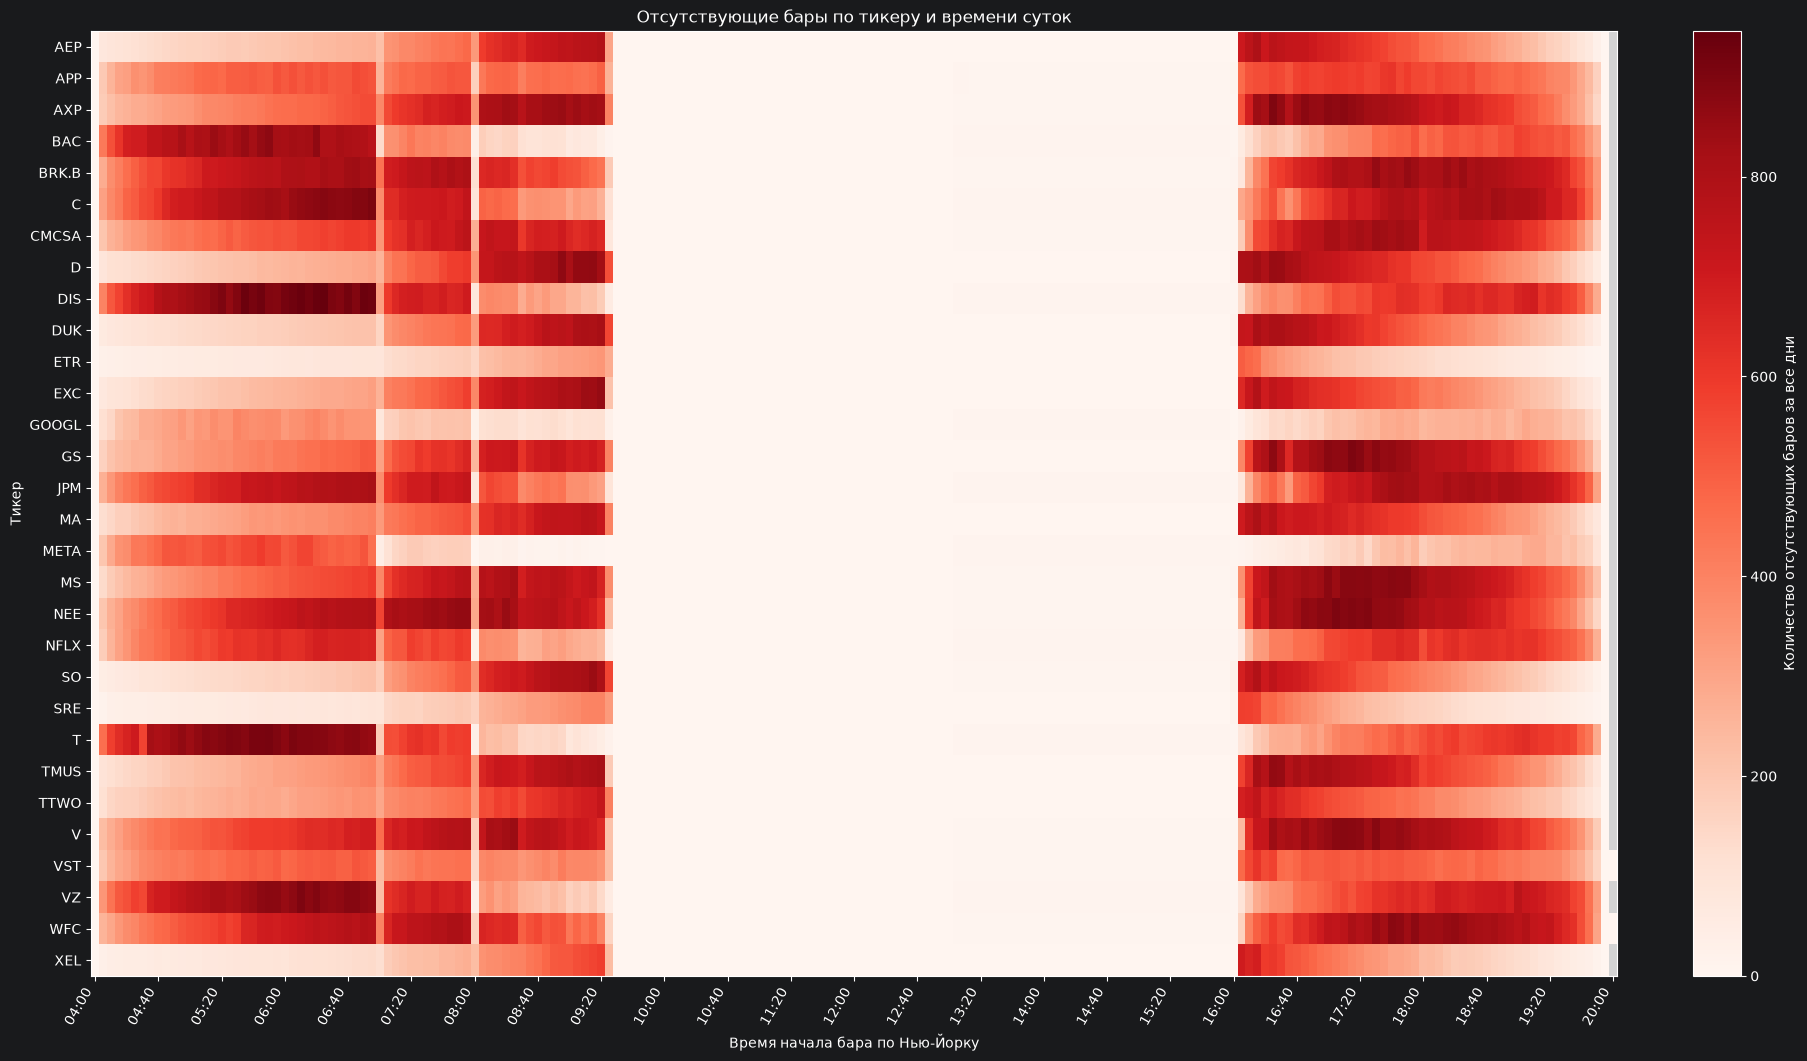

In [79]:
# actual: 1 — бар есть, 0 — отсутствует. Суммируем пропуски по дням.
missing_heatmap = (
    coverage_df.assign(missing=1 - coverage_df["actual"])
    .groupby(["ticker", "time_ny"])["missing"].sum()
    .unstack("time_ny")
    .sort_index().sort_index(axis=1)
)

cmap = plt.get_cmap("Reds").copy()
cmap.set_bad("lightgray")  # Нет ожидаемых наблюдений для этой пары тикер / время.
fig, ax = plt.subplots(
    figsize=(18, max(4, len(missing_heatmap) * 0.35)),
    constrained_layout=True,
)
image = ax.imshow(
    missing_heatmap.to_numpy(dtype=float),
    aspect="auto", interpolation="nearest", cmap=cmap,
    vmin=0, vmax=max(1, missing_heatmap.max().max()),
)
ax.set_yticks(range(len(missing_heatmap)), missing_heatmap.index)
tick_step = max(1, len(missing_heatmap.columns) // 24)
positions = list(range(0, len(missing_heatmap.columns), tick_step))
ax.set_xticks(positions, missing_heatmap.columns[positions], rotation=60, ha="right")
ax.set(
    title="Отсутствующие бары по тикеру и времени суток",
    xlabel="Время начала бара по Нью-Йорку", ylabel="Тикер",
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Количество отсутствующих баров за все дни")
plt.show()



### Видим довольно интересную картину:
1. Начиная с 9 с копейками до 16 отсутствующих баров нет либо крайне мало.
2. Есть несколько похожих паттернов для утра:
    а. торги могут быть стабильны с 4 утра и ближе к 7 все больше отсутствующих баров
    б. либо наоборот, начиная с 4 утра много пропущенных баров и потом ситуация выправляется
3. Похожая ситуация после 16
4. По идее было бы логично, что то, что начинает торговаться с 4 часов должно заканчивать раньше, но так далеко не всегда, например ETR, SRE и XEL

### Надо будет более детально проанализировать в чем причина

### Теперь то же самое для фьючерсов

In [80]:
coverage_df, records_dict = coverage_by_time(futures_15_min)

100%|██████████| 10637/10637 [00:03<00:00, 3317.15it/s]


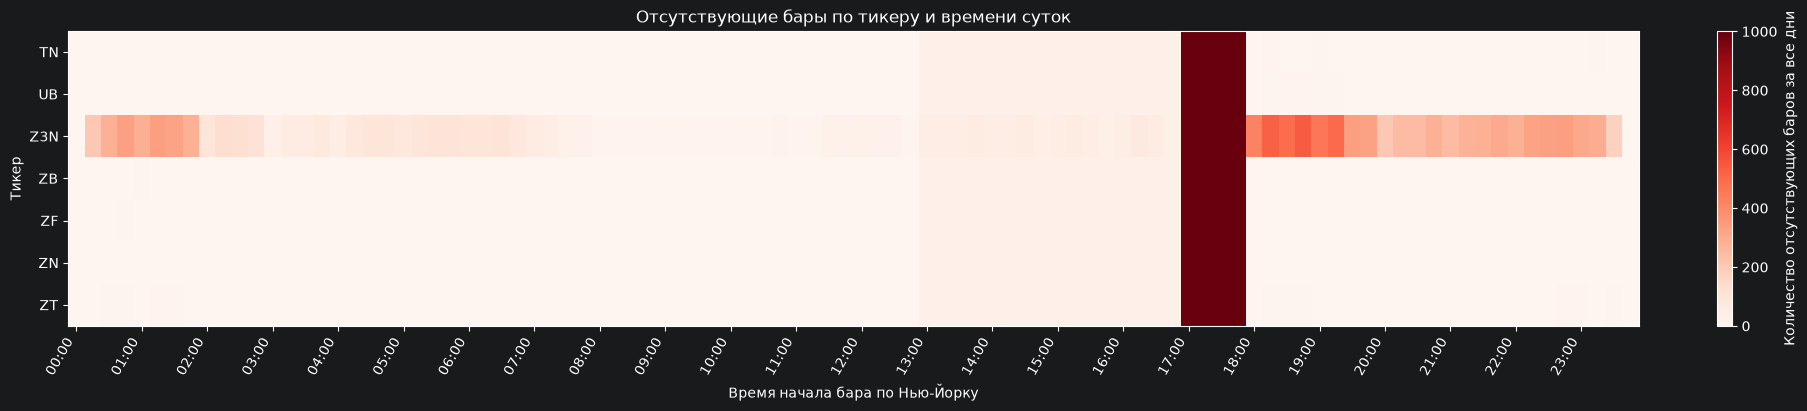

In [81]:
# actual: 1 — бар есть, 0 — отсутствует. Суммируем пропуски по дням.
missing_heatmap = (
    coverage_df.assign(missing=1 - coverage_df["actual"])
    .groupby(["ticker", "time_ny"])["missing"].sum()
    .unstack("time_ny")
    .sort_index().sort_index(axis=1)
)

cmap = plt.get_cmap("Reds").copy()
cmap.set_bad("lightgray")  # Нет ожидаемых наблюдений для этой пары тикер / время.
fig, ax = plt.subplots(
    figsize=(18, max(4, len(missing_heatmap) * 0.35)),
    constrained_layout=True,
)
image = ax.imshow(
    missing_heatmap.to_numpy(dtype=float),
    aspect="auto", interpolation="nearest", cmap=cmap,
    vmin=0, vmax=max(1, missing_heatmap.max().max()),
)
ax.set_yticks(range(len(missing_heatmap)), missing_heatmap.index)
tick_step = max(1, len(missing_heatmap.columns) // 24)
positions = list(range(0, len(missing_heatmap.columns), tick_step))
ax.set_xticks(positions, missing_heatmap.columns[positions], rotation=60, ha="right")
ax.set(
    title="Отсутствующие бары по тикеру и времени суток",
    xlabel="Время начала бара по Нью-Йорку", ylabel="Тикер",
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Количество отсутствующих баров за все дни")
plt.show()

### Для фьючерсов выводы несколько другие:
1. Они торгуются почти целые сутки кроме перерыва с 17 до 18 по нью йорку
2. с 13 до 17 все-таки есть относительно небольшое кол-во пропусков
3. Z3N фьючерс имеет много пропусков. Надо проанализировать с чем это может быть связано

### P.s. Z3N — фьючерс на трёхлетние казначейские облигации США, мб в этом и есть ключ

## 3. Объемы

In [111]:
data = stocks_1_hour.copy()

data["hour"] = data["ny_time"].dt.hour
data["day_of_week"] = data["ny_time"].dt.dayofweek  # 0 — понедельник
data["month"] = data["ny_time"].dt.month
data["season"] = data["month"].map({
    12: "Зима", 1: "Зима", 2: "Зима",
    3: "Весна", 4: "Весна", 5: "Весна",
    6: "Лето", 7: "Лето", 8: "Лето",
    9: "Осень", 10: "Осень", 11: "Осень",
})

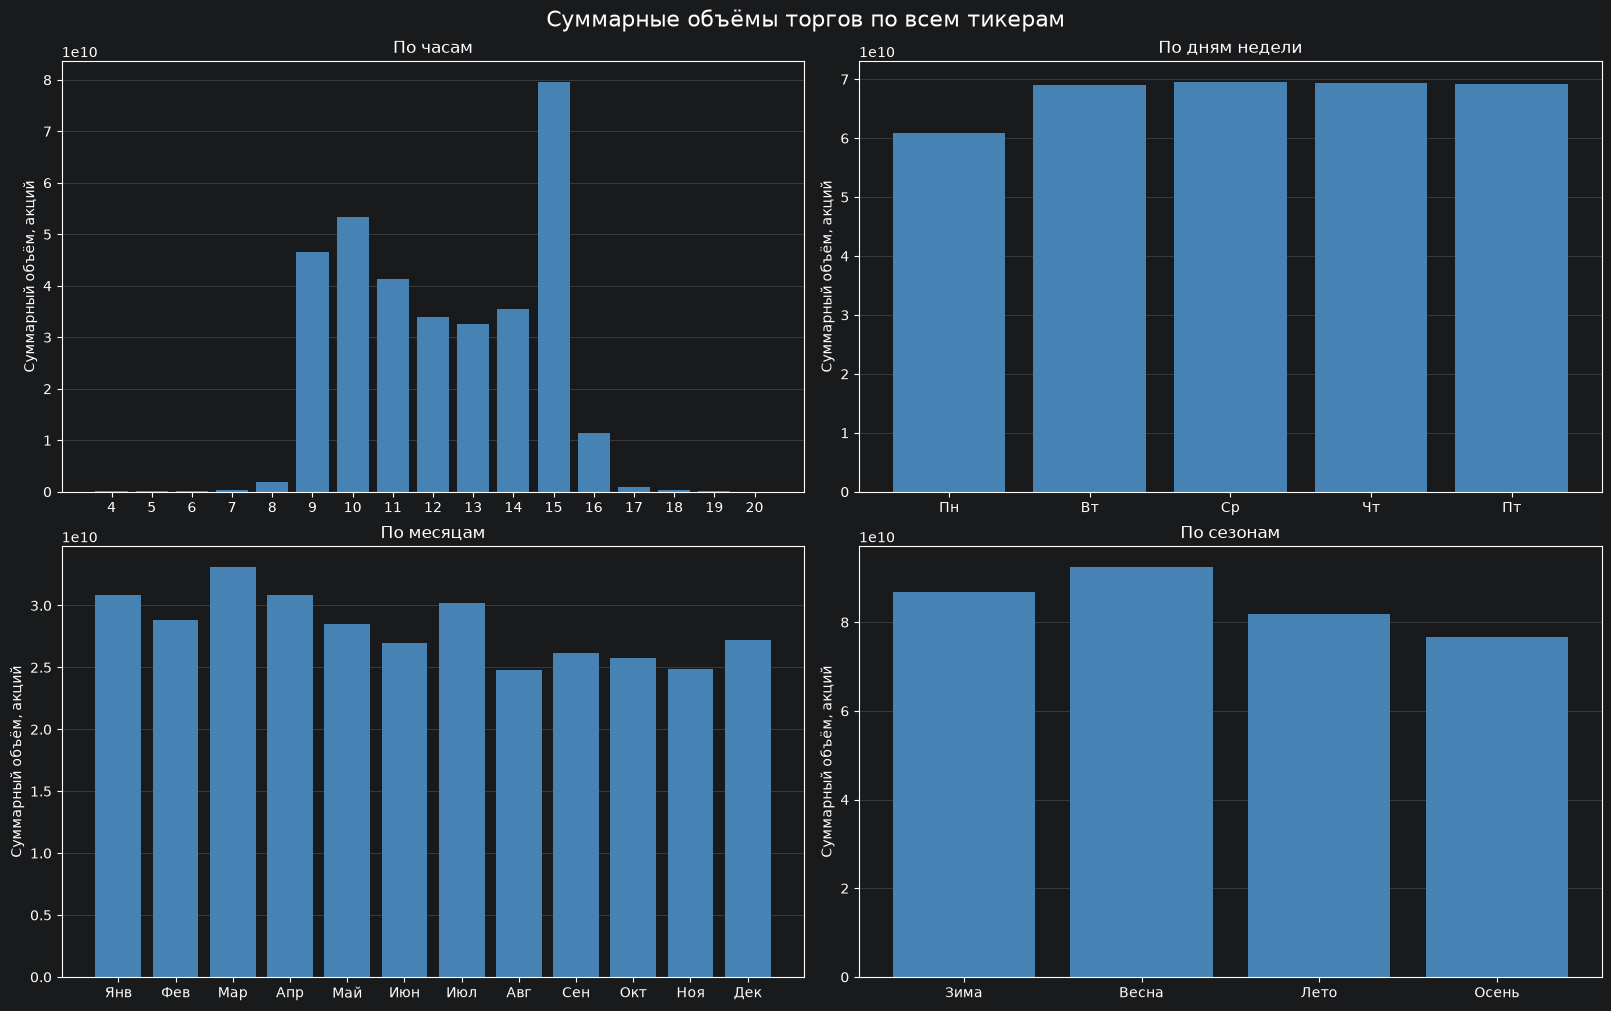

In [112]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

settings = [
    ("hour", sorted(data["hour"].unique()), None, "По часам"),
    ("day_of_week", range(5), ["Пн", "Вт", "Ср", "Чт", "Пт"], "По дням недели"),
    ("month", range(1, 13),
     ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
      "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"], "По месяцам"),
    ("season", ["Зима", "Весна", "Лето", "Осень"], None, "По сезонам"),
]

for ax, (column, order, labels, title) in zip(axes.flat, settings):
    volumes = data.groupby(column)["volume"].sum().reindex(order)

    ax.bar(range(len(volumes)), volumes, color="steelblue")
    ax.set_xticks(
        range(len(volumes)),
        labels if labels is not None else volumes.index,
    )
    ax.set_title(title)
    ax.set_ylabel("Суммарный объём, акций")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle("Суммарные объёмы торгов по всем тикерам", fontsize=16)
plt.show()

### Не знаю что тут комментировать. Все видно из графиков.
### Интересно распределение совокупного объема по часам. Видим 2 пика: в 10 и в 15. После 15 объем стремительно падает.
### Пока не знаю точно в чем причина. Мб это связано с часовыми поясами. Как раз в 15 по Нью Йорку в Лондоне уже 20, по идее там должны заканчиваться торги.

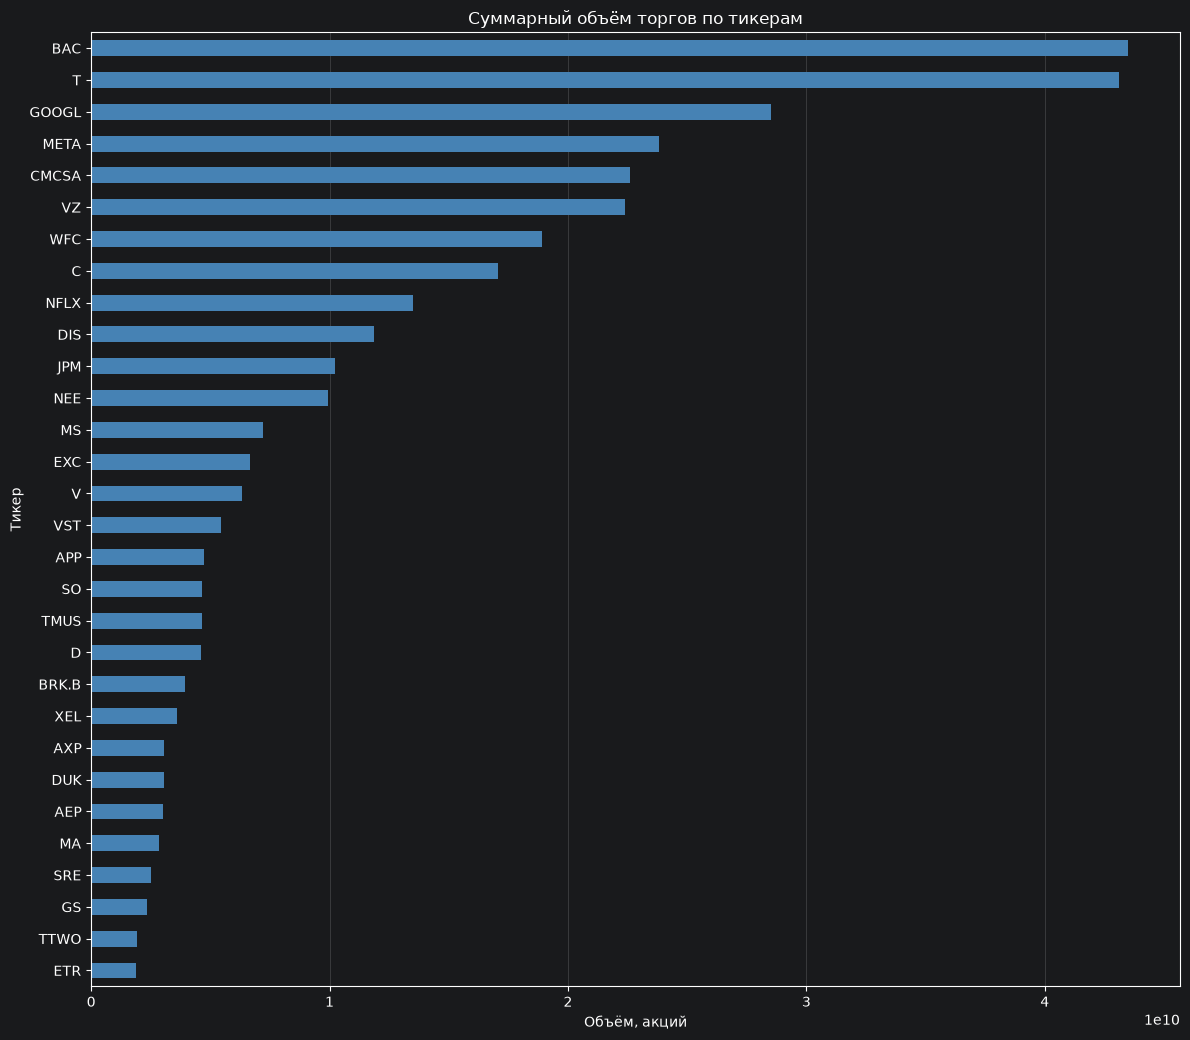

In [113]:
volumes = data.groupby("ticker")["volume"].sum().sort_values()

fig, ax = plt.subplots(figsize=(12, max(4, len(volumes) * 0.35)))
volumes.plot.barh(ax=ax, color="steelblue")

ax.set(
    title="Суммарный объём торгов по тикерам",
    xlabel="Объём, акций",
    ylabel="Тикер",
)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### На удивление Google или Meta не на первом месте по объемам. Вот несколько компаний, которые в топе и чье название я не понял изначально по тикеру

| Тикер | Компания | Основная деятельность |
|---|---|---|
| **BAC** | Bank of America | Банковские и финансовые услуги |
| **T** | AT&T | Мобильная связь и интернет |
| **CMCSA** | Comcast | Интернет, кабельное телевидение, медиабизнес NBCUniversal |
| **VZ** | Verizon Communications | Мобильная связь и интернет |
| **WFC** | Wells Fargo | Банковские и финансовые услуги |
| **C** | Citigroup | Международная банковская группа, бренд Citi |
| **DIS** | The Walt Disney Company | Кино, телевидение, стриминг и парки развлечений |
| **NEE** | NextEra Energy | Электроэнергетика, включая возобновляемые источники |

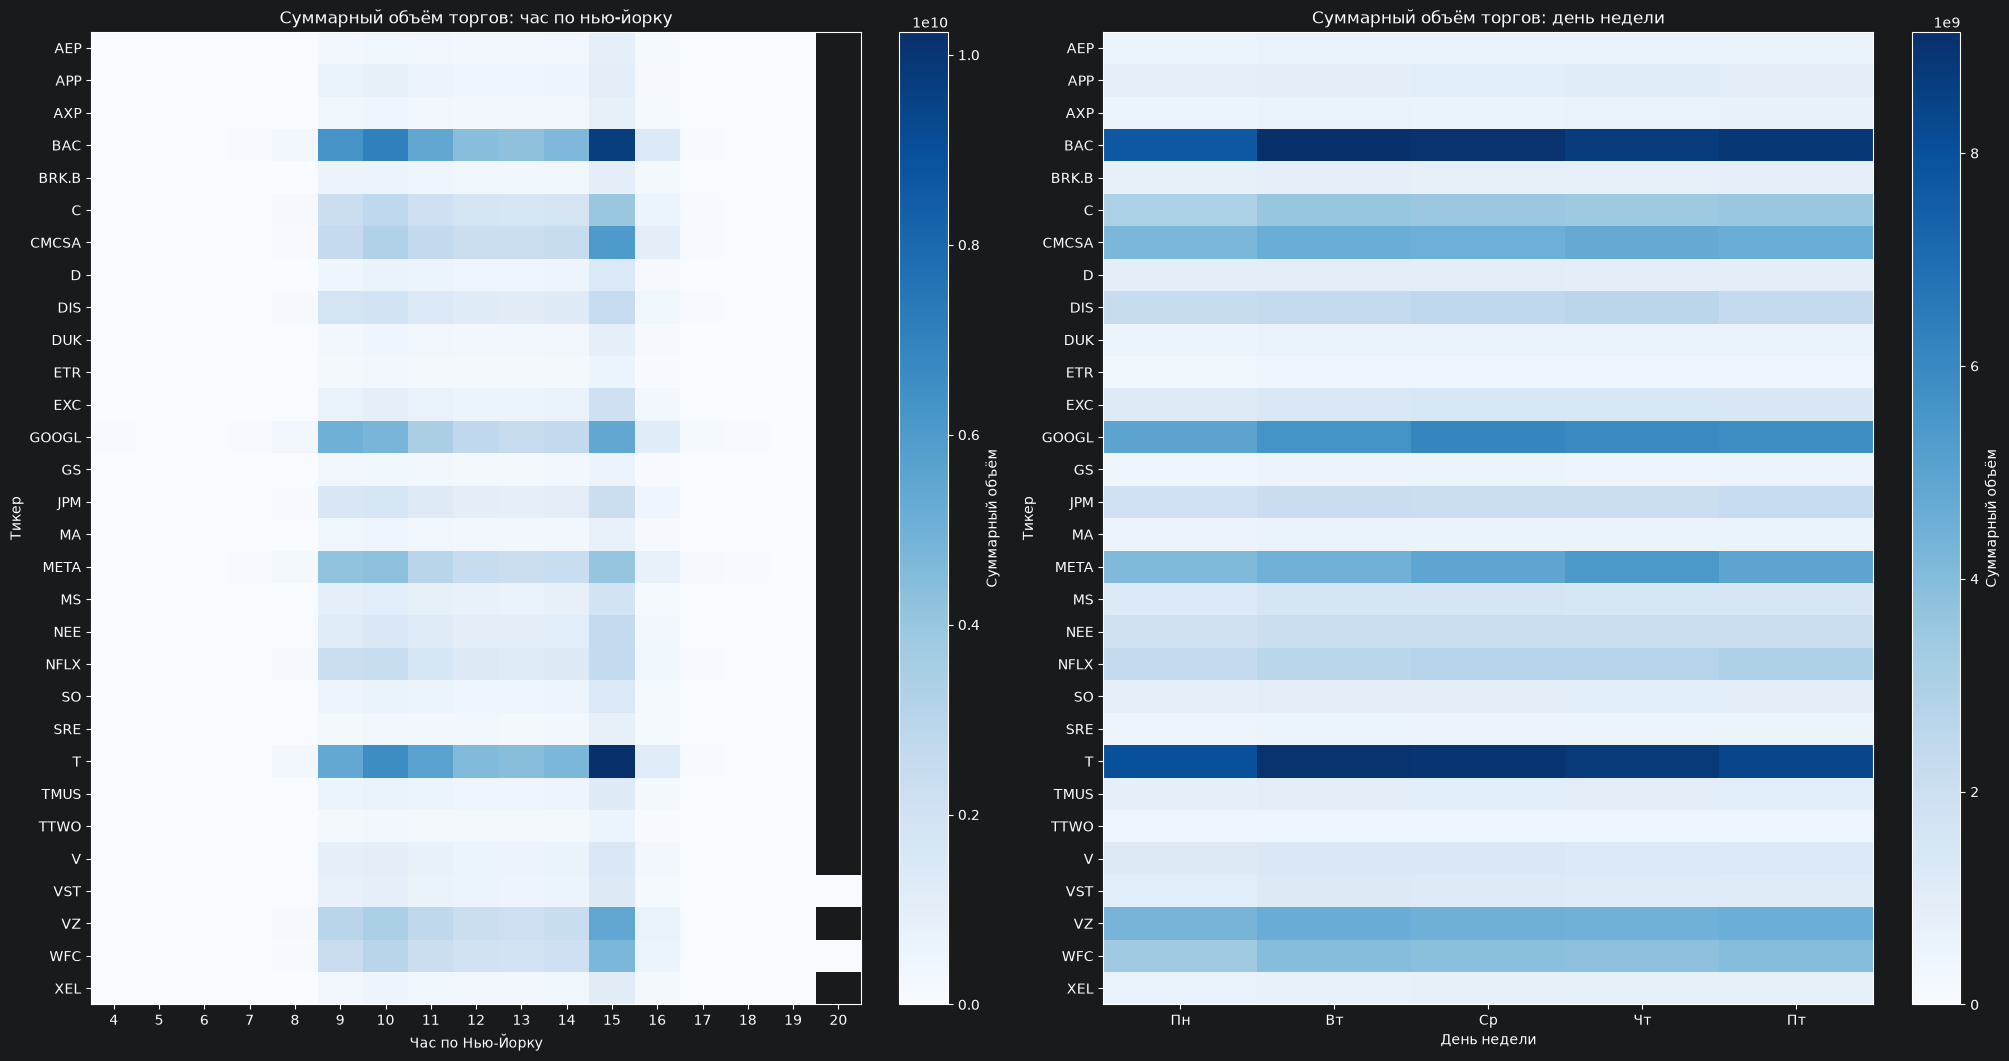

In [115]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, max(4, data["ticker"].nunique() * 0.35)),
    constrained_layout=True,
)

settings = [
    ("hour", sorted(data["hour"].unique()), None, "Час по Нью-Йорку"),
    ("day_of_week", range(5), ["Пн", "Вт", "Ср", "Чт", "Пт"], "День недели"),
]

for ax, (column, order, labels, xlabel) in zip(axes, settings):
    volume_heatmap = (
        data.groupby(["ticker", column])["volume"]
        .sum()
        .unstack(column)
        .sort_index()
        .reindex(columns=order)
    )

    image = ax.imshow(
        volume_heatmap,
        aspect="auto",
        cmap="Blues",
        interpolation="nearest",
        vmin=0,
    )

    ax.set_xticks(
        range(len(volume_heatmap.columns)),
        labels if labels is not None else volume_heatmap.columns,
    )
    ax.set_yticks(range(len(volume_heatmap)), volume_heatmap.index)
    ax.set(
        title=f"Суммарный объём торгов: {xlabel.lower()}",
        xlabel=xlabel,
        ylabel="Тикер",
    )
    ax.grid(False)

    fig.colorbar(image, ax=ax, label="Суммарный объём")

plt.show()

### Здесь получаем считай объединение по предыдущим графикам.
### Интересно, что одна и та же бумага торгуется однородно в течение недели, но разнородно в течение суток.

In [116]:
data = futures_1_hour.copy()

data["hour"] = data["ny_time"].dt.hour
data["day_of_week"] = data["ny_time"].dt.dayofweek  # 0 — понедельник
data["month"] = data["ny_time"].dt.month
data["season"] = data["month"].map({
    12: "Зима", 1: "Зима", 2: "Зима",
    3: "Весна", 4: "Весна", 5: "Весна",
    6: "Лето", 7: "Лето", 8: "Лето",
    9: "Осень", 10: "Осень", 11: "Осень",
})

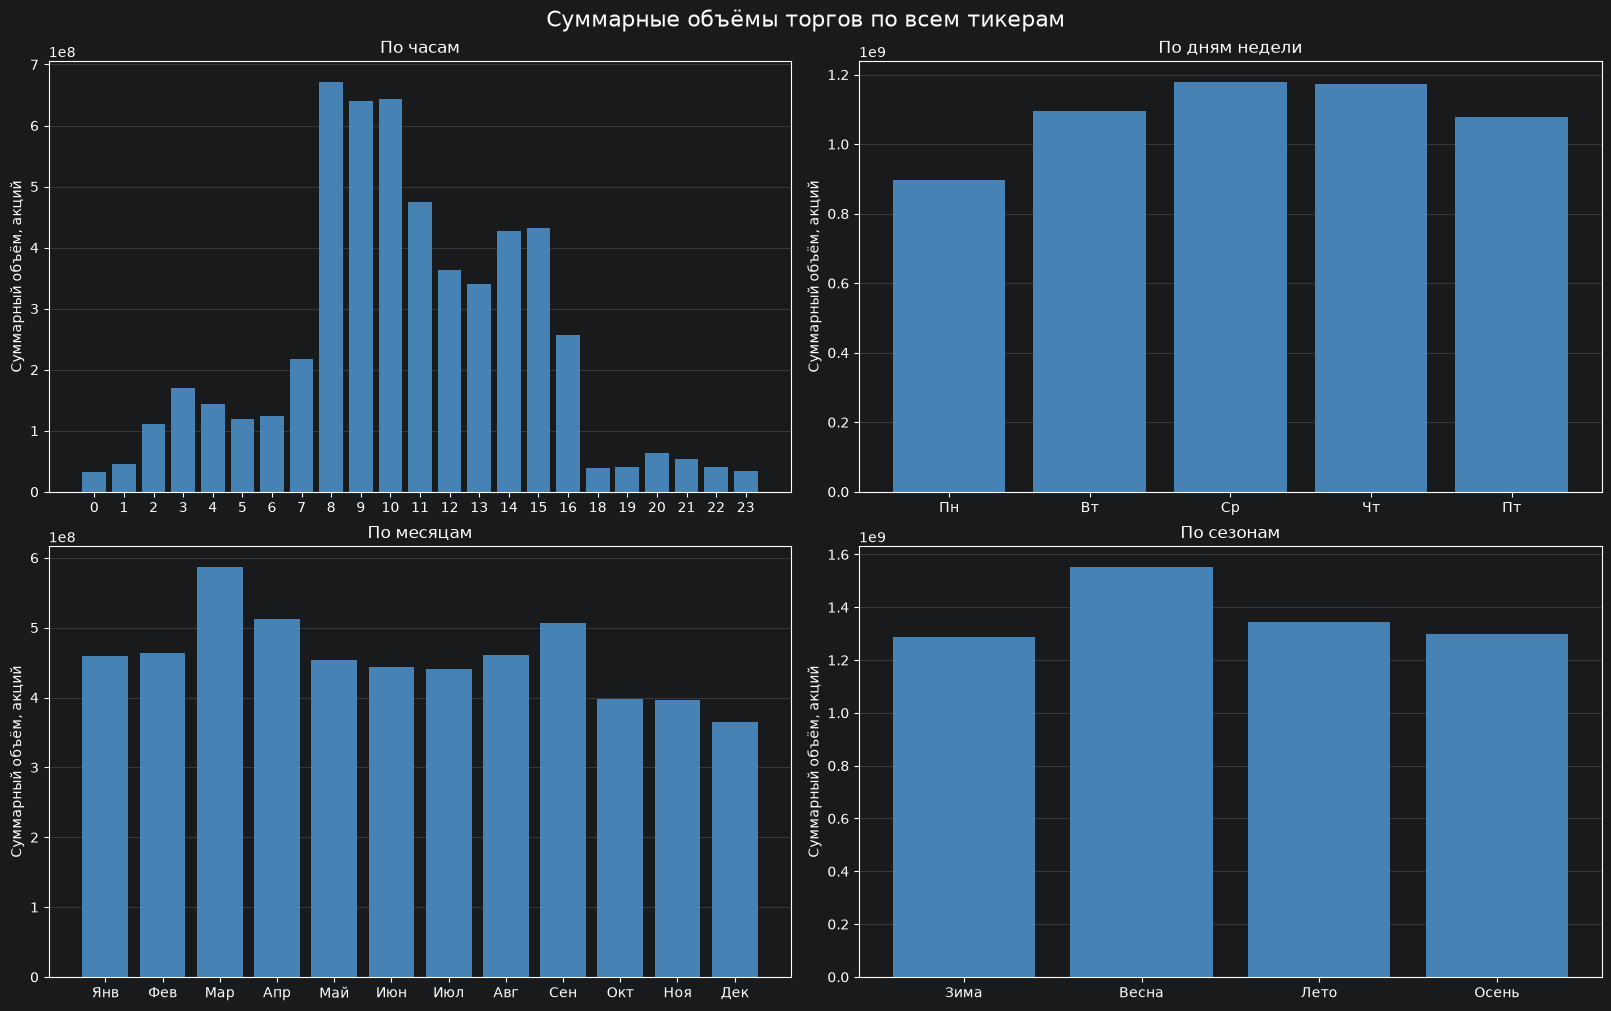

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

settings = [
    ("hour", sorted(data["hour"].unique()), None, "По часам"),
    ("day_of_week", range(5), ["Пн", "Вт", "Ср", "Чт", "Пт"], "По дням недели"),
    ("month", range(1, 13),
     ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
      "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"], "По месяцам"),
    ("season", ["Зима", "Весна", "Лето", "Осень"], None, "По сезонам"),
]

for ax, (column, order, labels, title) in zip(axes.flat, settings):
    volumes = data.groupby(column)["volume"].sum().reindex(order)

    ax.bar(range(len(volumes)), volumes, color="steelblue")
    ax.set_xticks(
        range(len(volumes)),
        labels if labels is not None else volumes.index,
    )
    ax.set_title(title)
    ax.set_ylabel("Суммарный объём, акций")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle("Суммарные объёмы торгов по всем тикерам", fontsize=16)
plt.show()

### В отличие от акций у фьючерсов больше активных часов. Также наибольший саовокупный объем приходится на 8 часов и далее сокращается. После 16 часов стремительная просадка.
### Есть и различия по месяцам. По акциям минимум в августе. По фьючерсам минимум в декабре

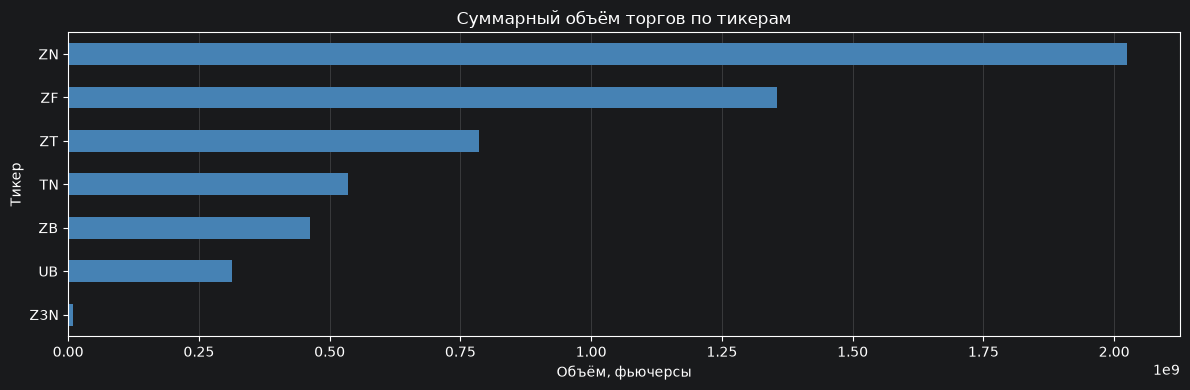

In [118]:
volumes = data.groupby("ticker")["volume"].sum().sort_values()

fig, ax = plt.subplots(figsize=(12, max(4, len(volumes) * 0.35)))
volumes.plot.barh(ax=ax, color="steelblue")

ax.set(
    title="Суммарный объём торгов по тикерам",
    xlabel="Объём, фьючерсы",
    ylabel="Тикер",
)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Больше всего торгуются фьючерсы на 10 летние казначейские облигации США
### Странно почему так мало на 3-летные

| Тикер | Название | Описание |
|---|---|---|
| **ZT** | 2-Year U.S. Treasury Note Futures | Фьючерс на 2-летние казначейские облигации США |
| **Z3N** | 3-Year U.S. Treasury Note Futures | Фьючерс на 3-летние казначейские облигации США |
| **ZF** | 5-Year U.S. Treasury Note Futures | Фьючерс на 5-летние казначейские облигации США |
| **ZN** | 10-Year U.S. Treasury Note Futures | Фьючерс на 10-летние казначейские облигации США |
| **TN** | Ultra 10-Year U.S. Treasury Note Futures | Фьючерс Ultra на 10-летние казначейские облигации США |
| **ZB** | U.S. Treasury Bond Futures | Фьючерс на долгосрочные казначейские облигации США, традиционно называемый 30-летним |
| **UB** | Ultra U.S. Treasury Bond Futures | Фьючерс Ultra на долгосрочные казначейские облигации США |

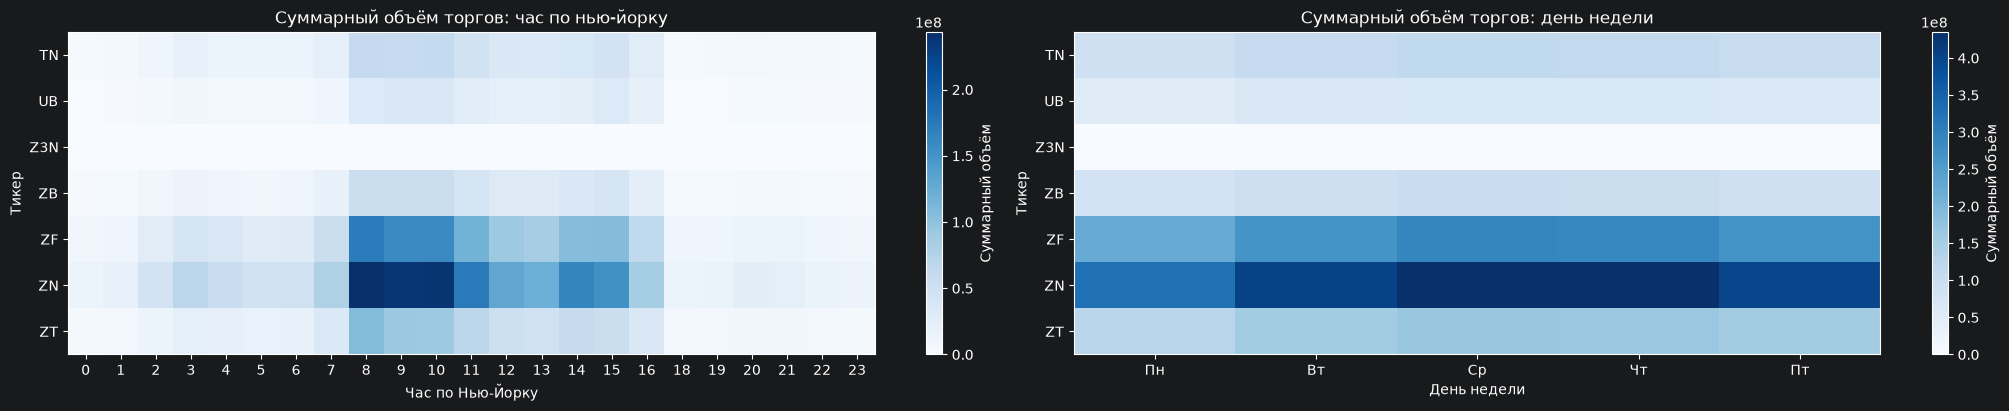

In [119]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, max(4, data["ticker"].nunique() * 0.35)),
    constrained_layout=True,
)

settings = [
    ("hour", sorted(data["hour"].unique()), None, "Час по Нью-Йорку"),
    ("day_of_week", range(5), ["Пн", "Вт", "Ср", "Чт", "Пт"], "День недели"),
]

for ax, (column, order, labels, xlabel) in zip(axes, settings):
    volume_heatmap = (
        data.groupby(["ticker", column])["volume"]
        .sum()
        .unstack(column)
        .sort_index()
        .reindex(columns=order)
    )

    image = ax.imshow(
        volume_heatmap,
        aspect="auto",
        cmap="Blues",
        interpolation="nearest",
        vmin=0,
    )

    ax.set_xticks(
        range(len(volume_heatmap.columns)),
        labels if labels is not None else volume_heatmap.columns,
    )
    ax.set_yticks(range(len(volume_heatmap)), volume_heatmap.index)
    ax.set(
        title=f"Суммарный объём торгов: {xlabel.lower()}",
        xlabel=xlabel,
        ylabel="Тикер",
    )
    ax.grid(False)

    fig.colorbar(image, ax=ax, label="Суммарный объём")

plt.show()

### По ZN и ZF видим крен по объемам в среду и четверг. У остальных более менее однородно в течение недели.
### По ним же видим крен и по времени в сторону раннего утра

### 4.  Returns

In [138]:
def add_log_returns(df):

    data = df.sort_values(["ticker", "ny_time"]).copy()
    price = "adj_close" if df.attrs["asset_type"] == "stocks" else "close"
    step = pd.Timedelta(
        {"5min": 5, "15min": 15, "1hour": 60, "4hour": 240}
        [df.attrs["timeframe"]],
        unit="min",
    )

    grouped = data.groupby(["ticker", "ny_date"])
    previous_price = grouped[price].shift()
    previous_time = grouped["ny_time"].shift()

    continuous = (data["ny_time"] - previous_time).eq(step)

    data["log_return"] = np.log(
        data[price].where(data[price] > 0)
        / previous_price.where(previous_price > 0)
    ).where(continuous)

    return data[data['log_return'].notnull()]

In [139]:
stocks_5_min = add_log_returns(stocks_5_min)
stocks_15_min = add_log_returns(stocks_15_min)
stocks_1_hour = add_log_returns(stocks_1_hour)
stocks_4_hour = add_log_returns(stocks_4_hour)

futures_15_min = add_log_returns(futures_15_min)
futures_1_hour = add_log_returns(futures_1_hour)
futures_4_hour = add_log_returns(futures_4_hour)

In [141]:
def plot_log_returns_boxplots(df, column="log_return", showfliers=False):

    data = df.copy()
    data["hour"] = data["ny_time"].dt.hour
    data["day_of_week"] = data["ny_time"].dt.dayofweek
    data["month"] = data["ny_time"].dt.month

    settings = [
        ("day_of_week", range(7),
         ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], "По дням недели"),
        ("hour", range(24), None, "По часам — Нью-Йорк"),
        ("month", range(1, 13),
         ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
          "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"], "По месяцам"),
    ]

    fig, axes = plt.subplots(
        1, 3, figsize=(20, 5), constrained_layout=True
    )

    for ax, (group, order, labels, title) in zip(axes, settings):
        values, tick_labels = [], []

        for i, category in enumerate(order):
            returns = data.loc[data[group] == category, column].dropna()

            if not returns.empty:
                values.append(returns * 100)
                tick_labels.append(
                    labels[i] if labels is not None else str(category)
                )

        if values:
            ax.boxplot(
                values,
                tick_labels=tick_labels,
                showfliers=showfliers,
            )

        ax.set_title(title)
        ax.set_ylabel("Логарифмическая доходность × 100")
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.grid(axis="y", alpha=0.3)

    asset = df.attrs.get("asset_type", "")
    timeframe = df.attrs.get("timeframe", "")
    fig.suptitle(f"Распределение логарифмических доходностей · {asset} · {timeframe}")
    plt.show()

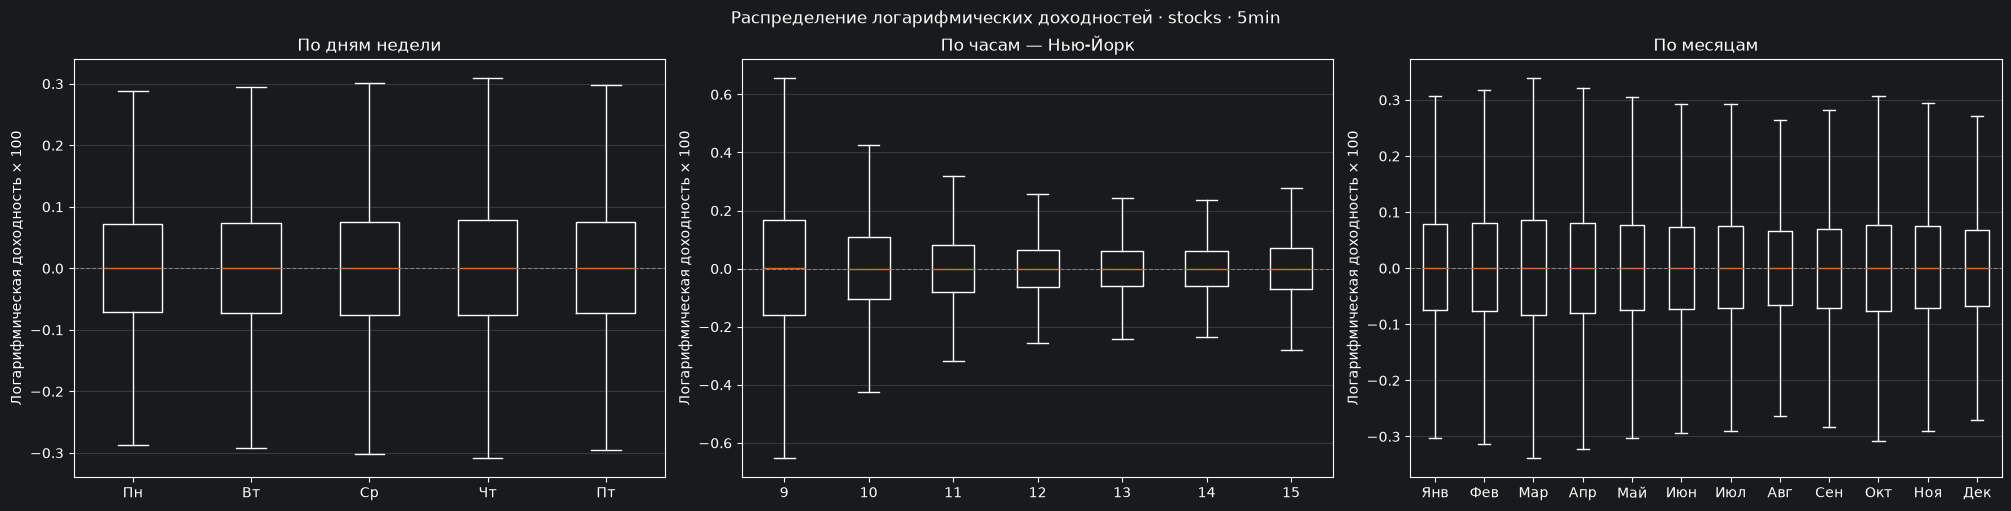

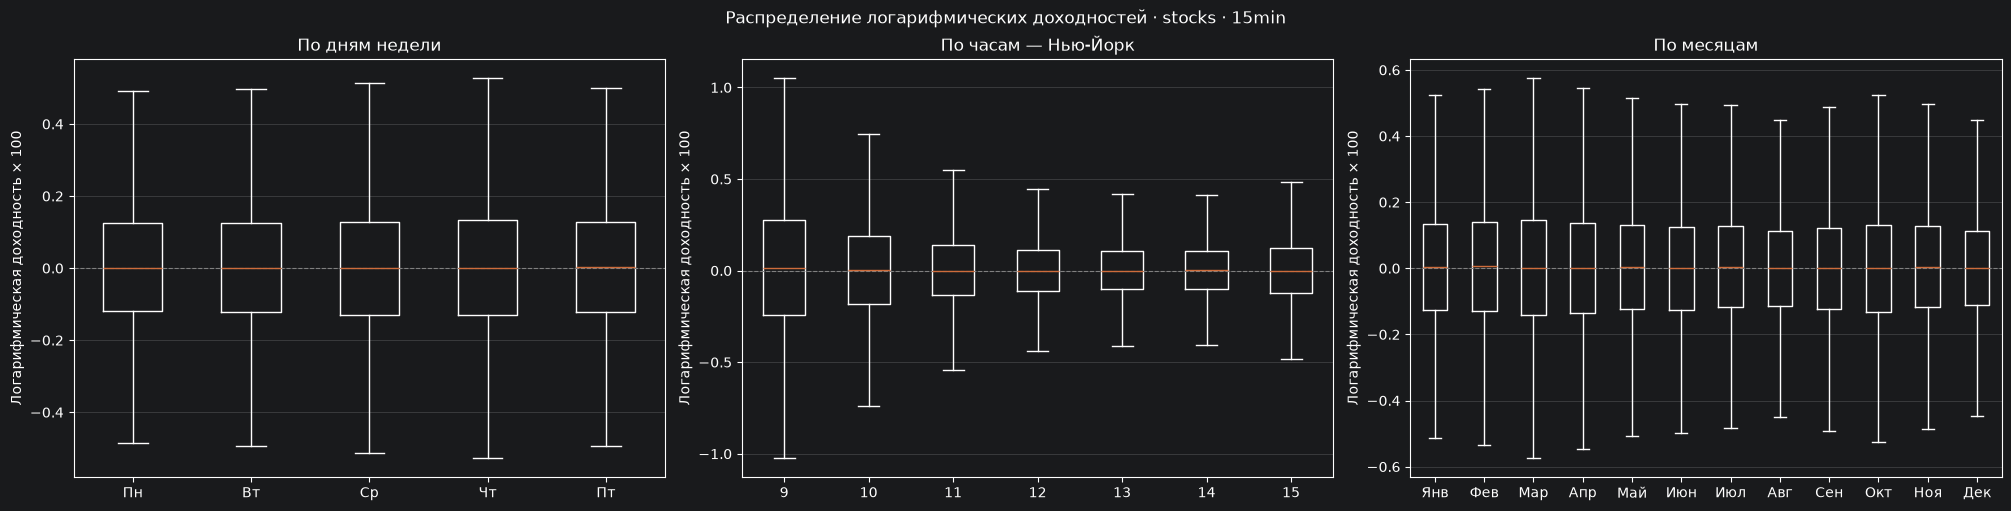

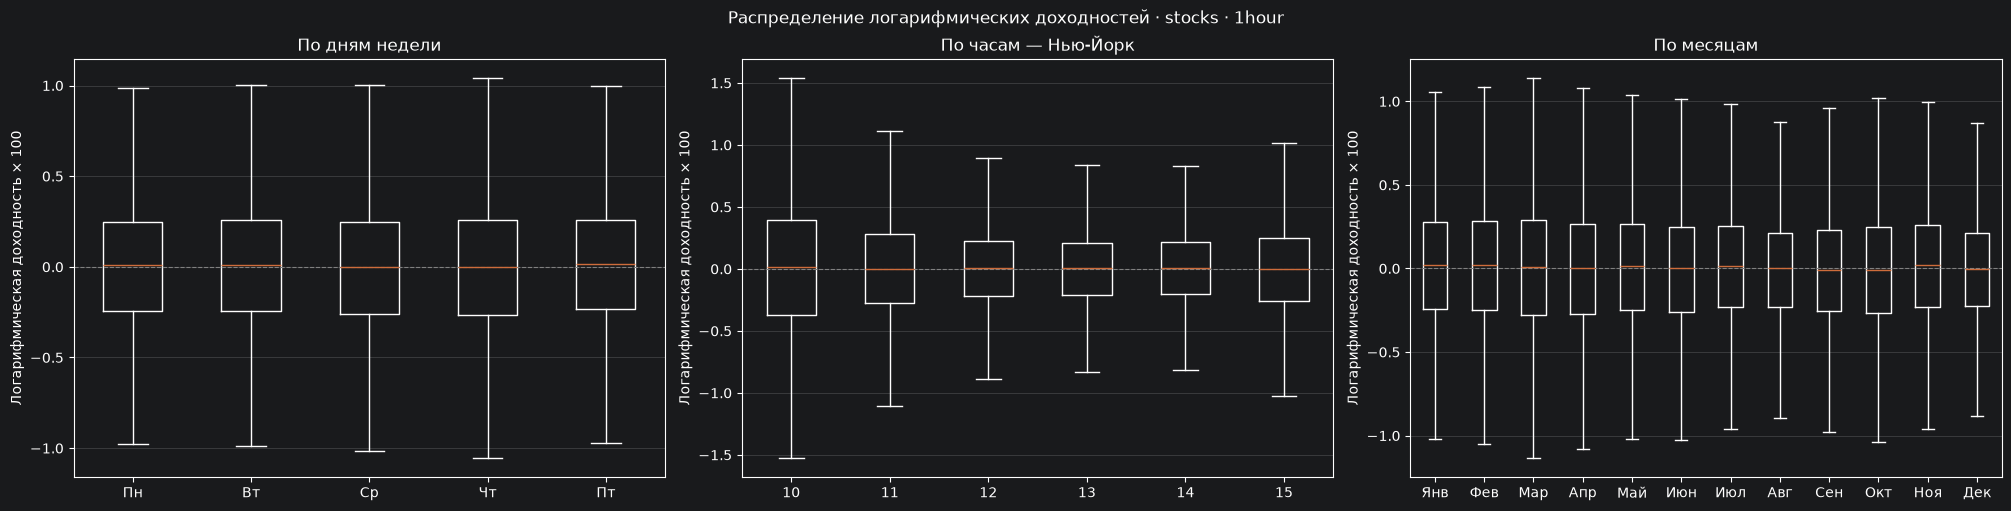

In [146]:
plot_log_returns_boxplots(stocks_5_min)
plot_log_returns_boxplots(stocks_15_min)
plot_log_returns_boxplots(stocks_1_hour)

### По 5 минутам:
1. Средняя лог доходность крайне близка к 0 вообще для всего (день недели, час , месяц)
2. По дням недели стандартное отклонение почти не отличается
3. А вот по часам отличается. В начале дня волатильность выше и к 12 стабилизируется
4. По месяцам волатильность переменная, но в целом ничего интересного

### По 15 минутам:
1. Рано утром в 9 средняя лог доходность больше 0. Но и стандартное отклонение наибольшее. В остальном так же как и для 5 мин.

### По часу:
1. Рано утром также средняя доходность выше 0. И волотильность наибольшая
2. По дням недели видно, что в среду и четверг средняя лог доходность ближе всего к 0, в остальные дни больше 0.
3. Январь, февраль, Май, Июль, Ноябрь имеют положительную среднюю лог доходность. А вот в сентябре и октябре ниже 0.

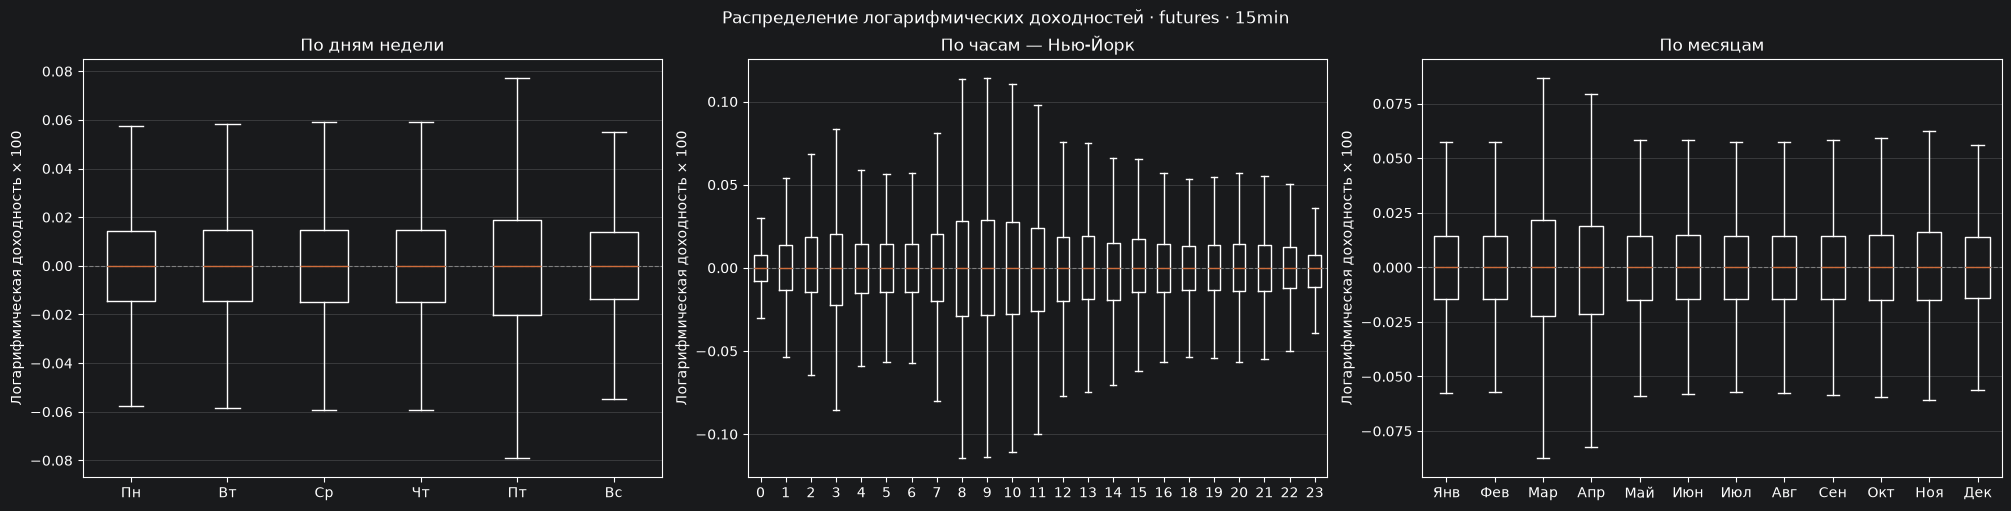

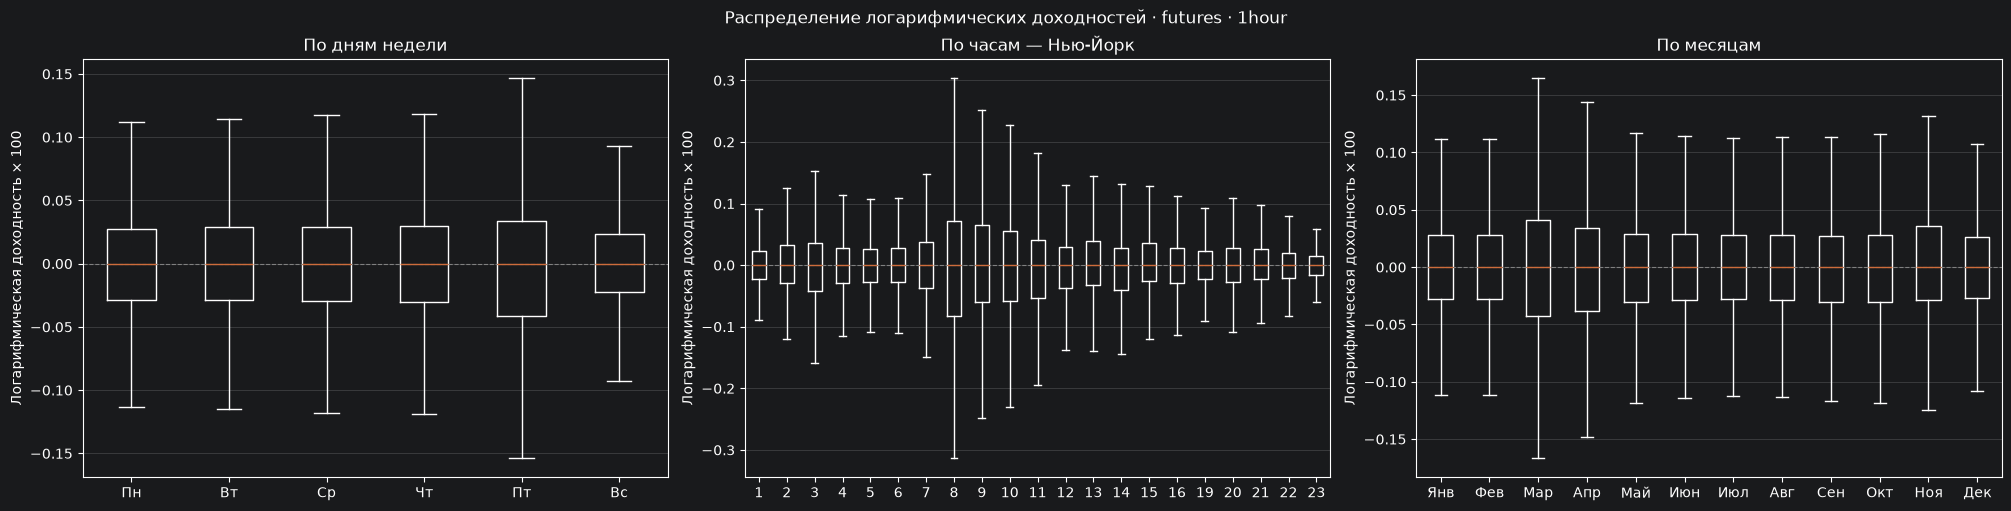

In [147]:
plot_log_returns_boxplots(futures_15_min)
plot_log_returns_boxplots(futures_1_hour)

### По фьючерсам везде средняя лог доходность крайне близка к 0. Отличия только в волатильности
### Самый волатильный день недели - пятница, час - 8, месяц - март

In [160]:
analysis = stocks_5_min.copy()

analysis["abs_return"] = analysis["log_return"].abs()

# Волатильность за последние 6 пятиминутных баров.
analysis["volatility_30"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(6, min_periods=6).std())
)
analysis["volatility_60"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(12, min_periods=12).std())
)
analysis["volatility_120"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(24, min_periods=24).std())
)

columns = ["log_return", "abs_return", "volatility_30", "volatility_60", "volatility_120", "volume"]

display(analysis[columns].corr(method="spearman").round(3))

,log_return,abs_return,volatility_30,volatility_60,volatility_120,volume
log_return,1.000,0.003,-0.002,-0.001,-0.000,0.001
abs_return,0.003,1.000,0.485,0.420,0.359,0.160
volatility_30,-0.002,0.485,1.000,0.841,0.719,0.183
volatility_60,-0.001,0.420,0.841,1.000,0.873,0.166
volatility_120,-0.000,0.359,0.719,0.873,1.000,0.128
volume,0.001,0.160,0.183,0.166,0.128,1.000


### Есть определенная корреляция между модулем лог доходности и волатильностью лог доходности за последние 30, 60, 120 мин. Особенно хорошо работают 30 мин

In [162]:
analysis = futures_15_min.copy()

analysis["abs_return"] = analysis["log_return"].abs()

# Волатильность за последние 6 пятиминутных баров.
analysis["volatility_30"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(6, min_periods=6).std())
)
analysis["volatility_60"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(12, min_periods=12).std())
)
analysis["volatility_120"] = (
    analysis.groupby(["ticker", "ny_date"])["log_return"]
    .transform(lambda s: s.rolling(24, min_periods=24).std())
)

columns = ["log_return", "abs_return", "volatility_30", "volatility_60", "volatility_120", "volume"]

display(analysis[columns].corr(method="spearman").round(3))

,log_return,abs_return,volatility_30,volatility_60,volatility_120,volume
log_return,1.000,-0.005,-0.002,-0.001,0.001,-0.003
abs_return,-0.005,1.000,0.624,0.585,0.550,0.238
volatility_30,-0.002,0.624,1.000,0.934,0.872,0.243
volatility_60,-0.001,0.585,0.934,1.000,0.942,0.215
volatility_120,0.001,0.550,0.872,0.942,1.000,0.178
volume,-0.003,0.238,0.243,0.215,0.178,1.000


### Фьючерсы показывают еще большую корреляцию. Но очень важно всегда помнить, что это еще не говорит о взаимосвязи на 100 процентов как и не говорит о том, что волатильность лучше подойдет для фьючей.
### Просто для фьючерсов ЛИНЕЙНАЯ зависимость более выражена

In [173]:
def plot_daily_close(df, ticker, start_date, end_date):
    import pandas as pd
    import matplotlib.pyplot as plt

    data = df.loc[df["ticker"] == ticker].copy()
    data["date"] = data["ny_time"].dt.normalize()

    daily_close = (
        data.sort_values("ny_time")
        .groupby("date")["close"]
        .last()
        .loc[start_date:end_date]
    )

    daily_close.plot(figsize=(14, 5), title=f"{ticker}: цена закрытия")
    plt.xlabel("Дата по Нью-Йорку")
    plt.ylabel("Цена закрытия")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

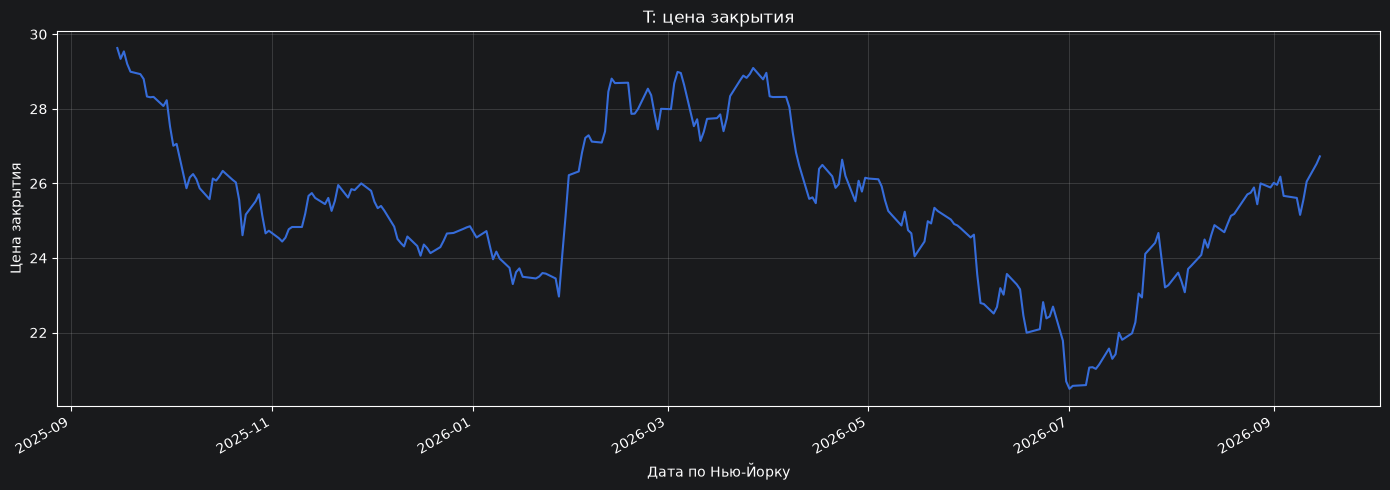

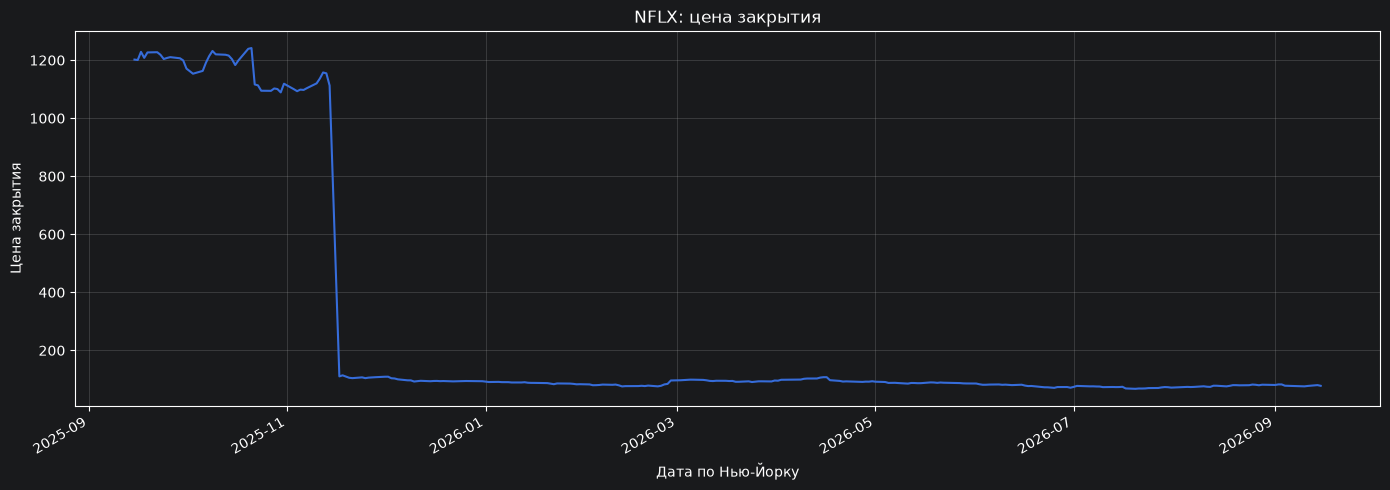

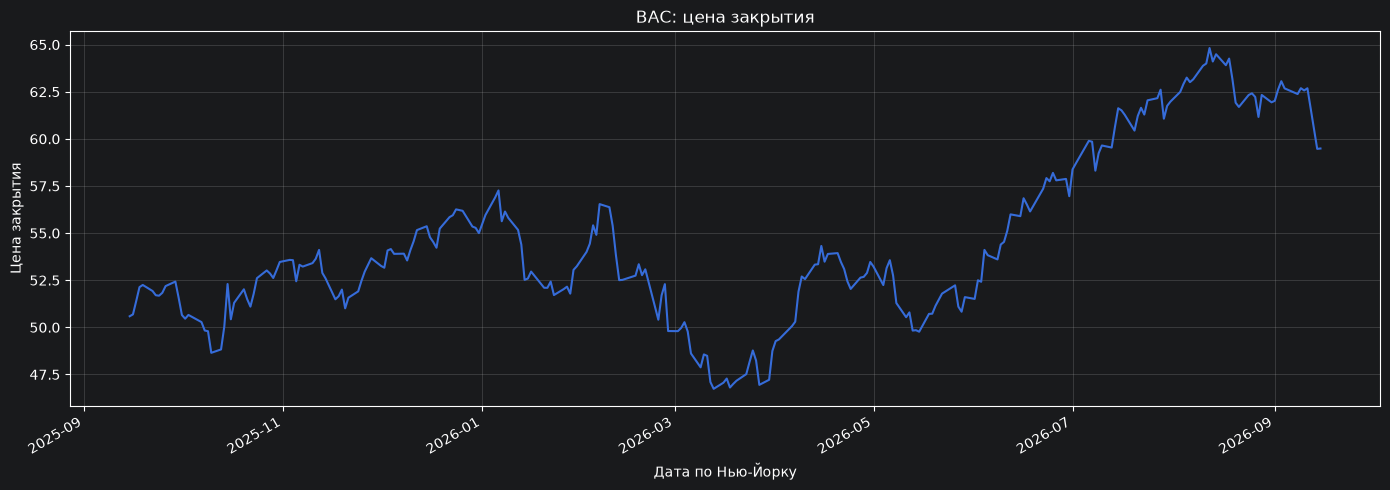

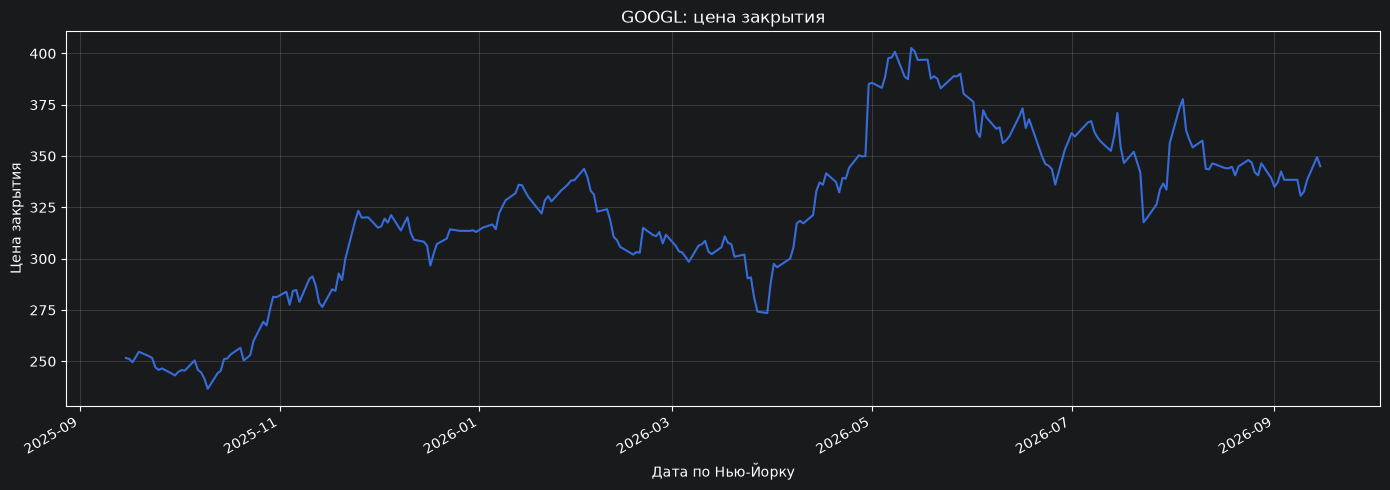

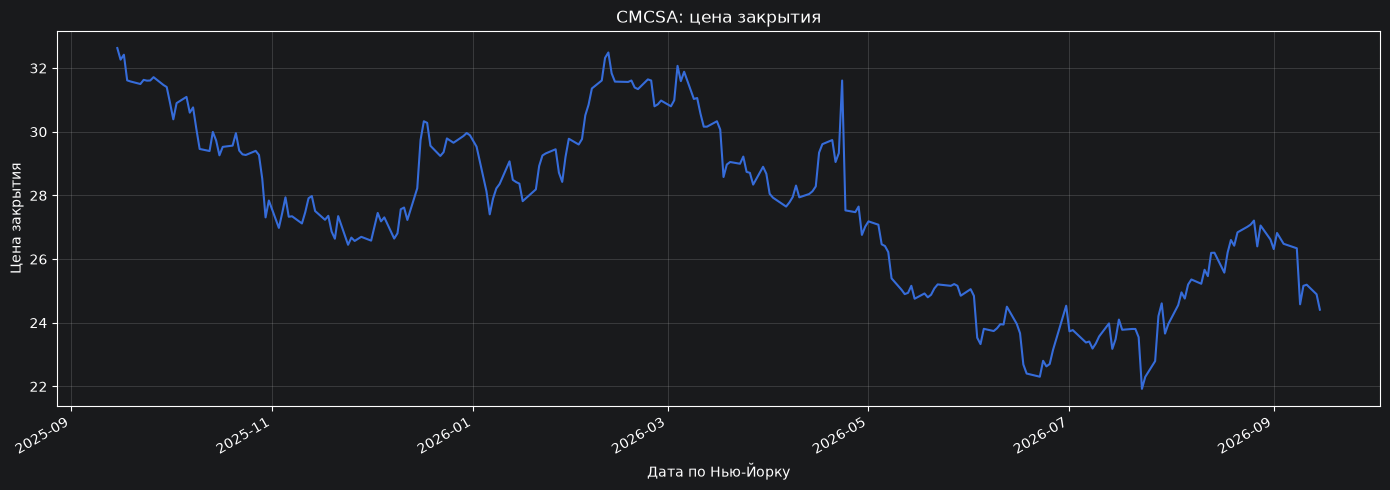

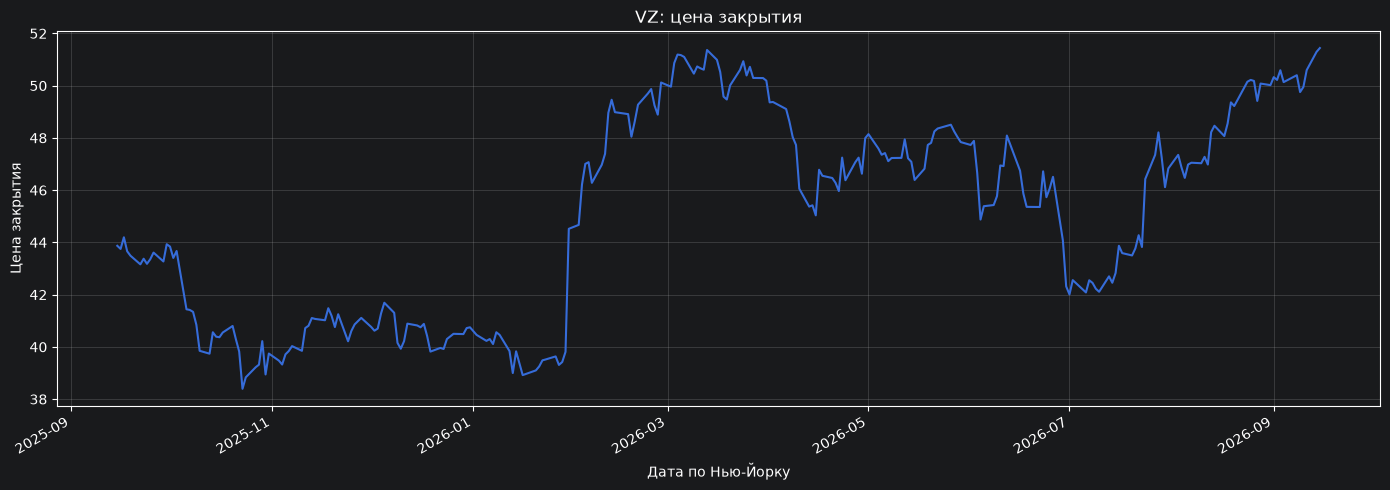

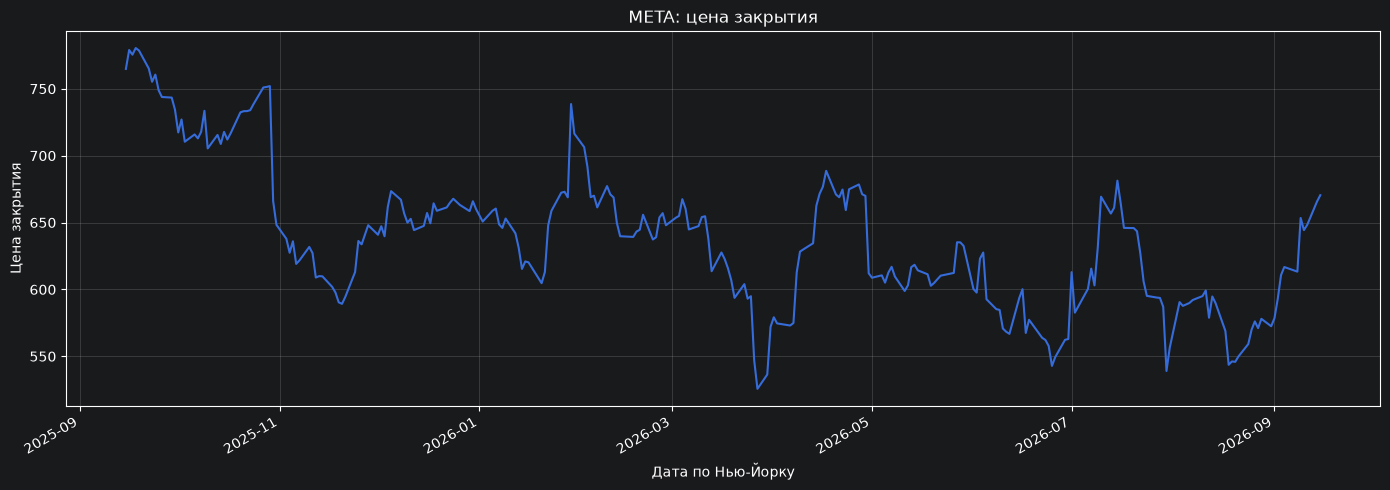

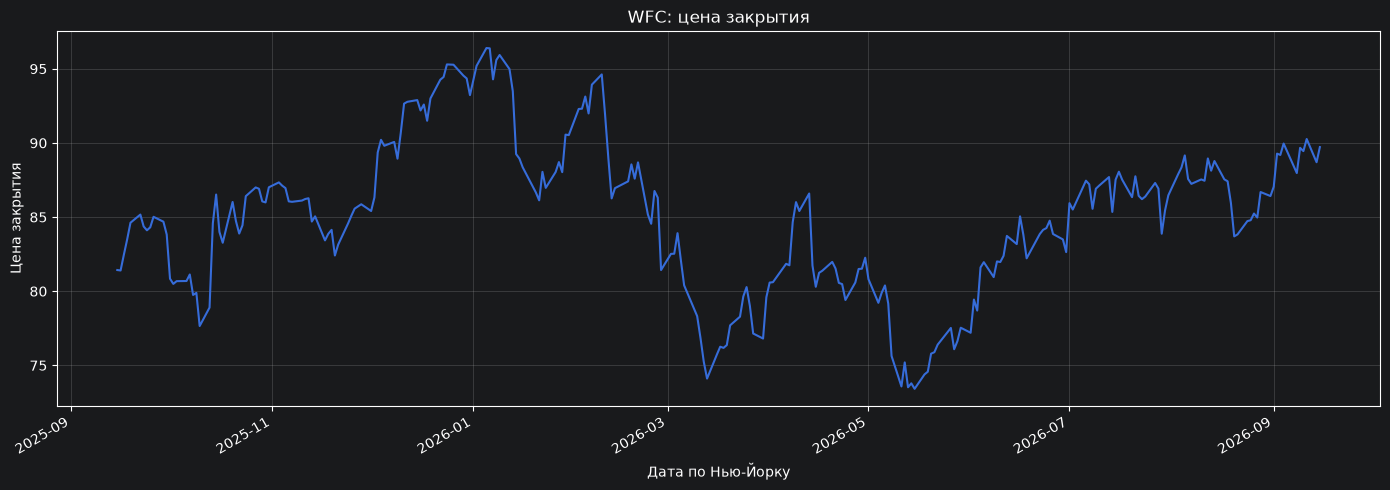

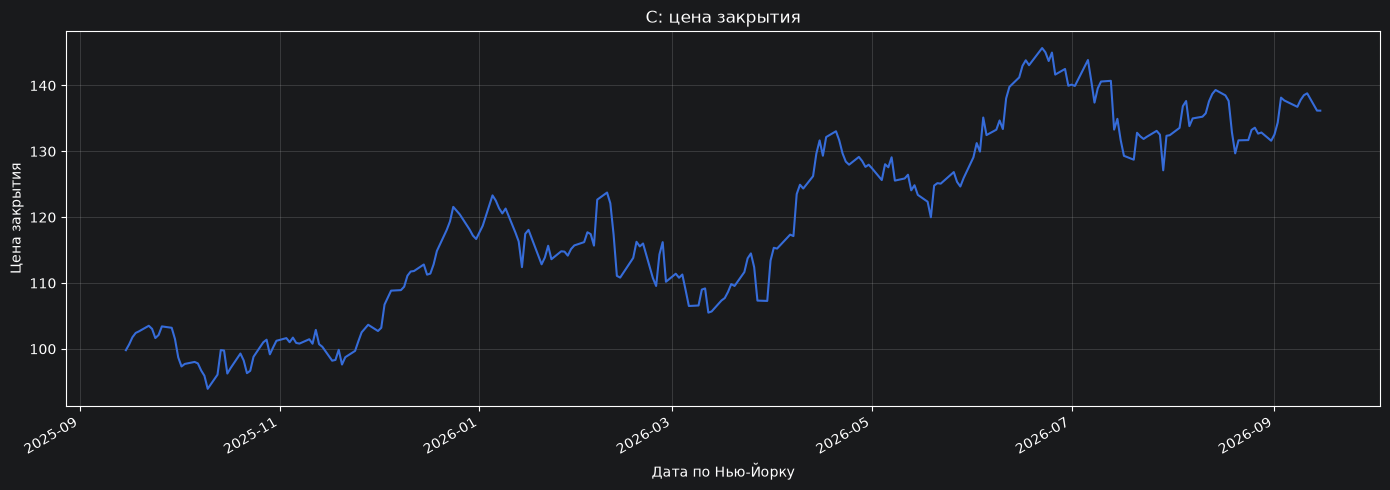

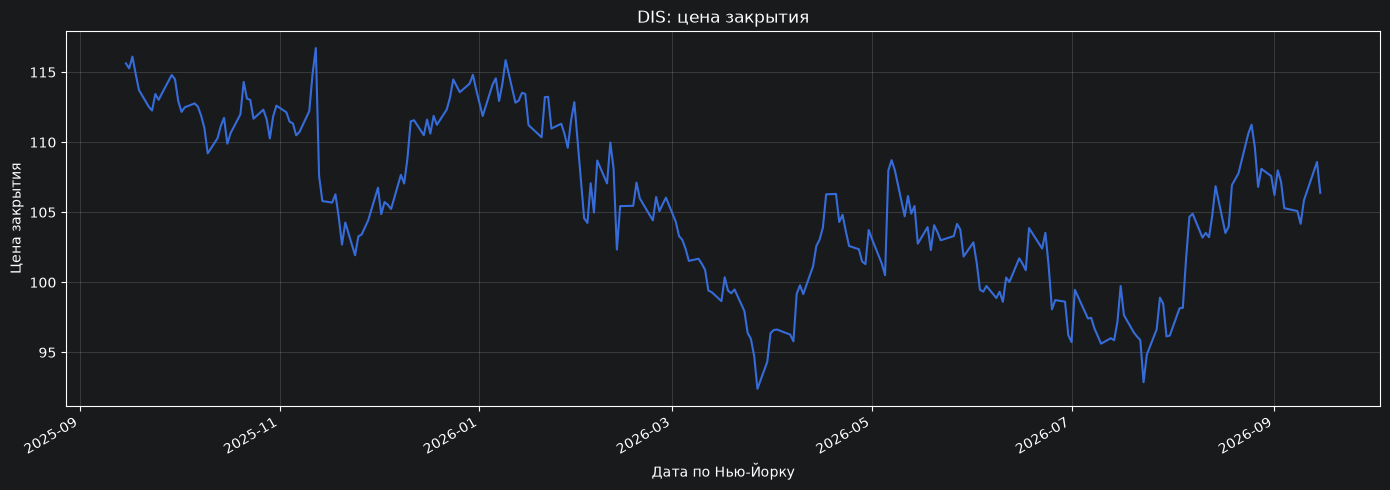

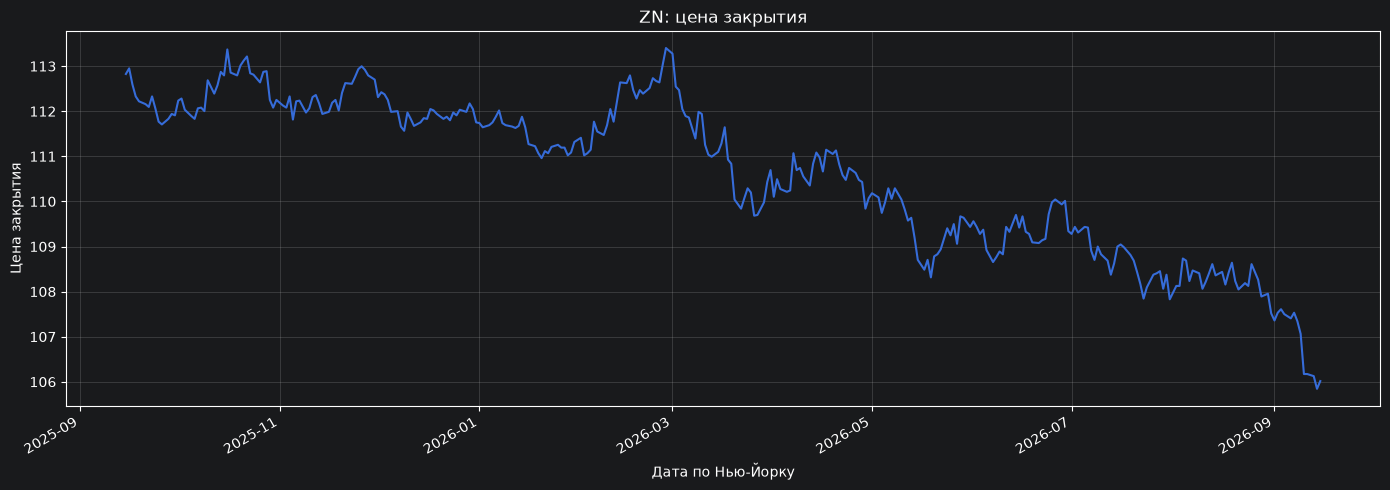

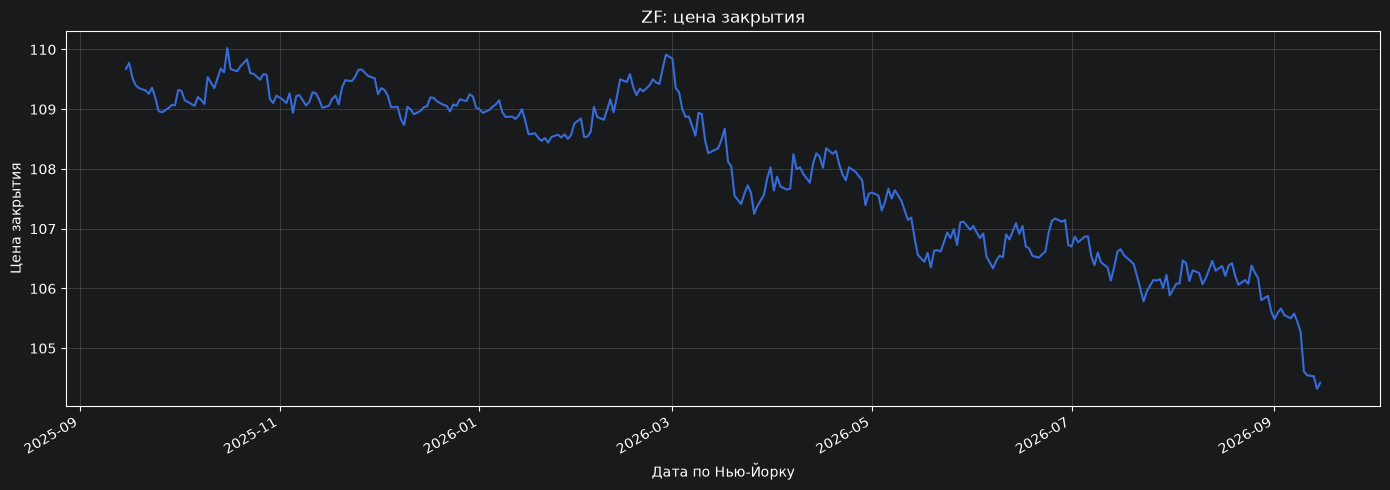

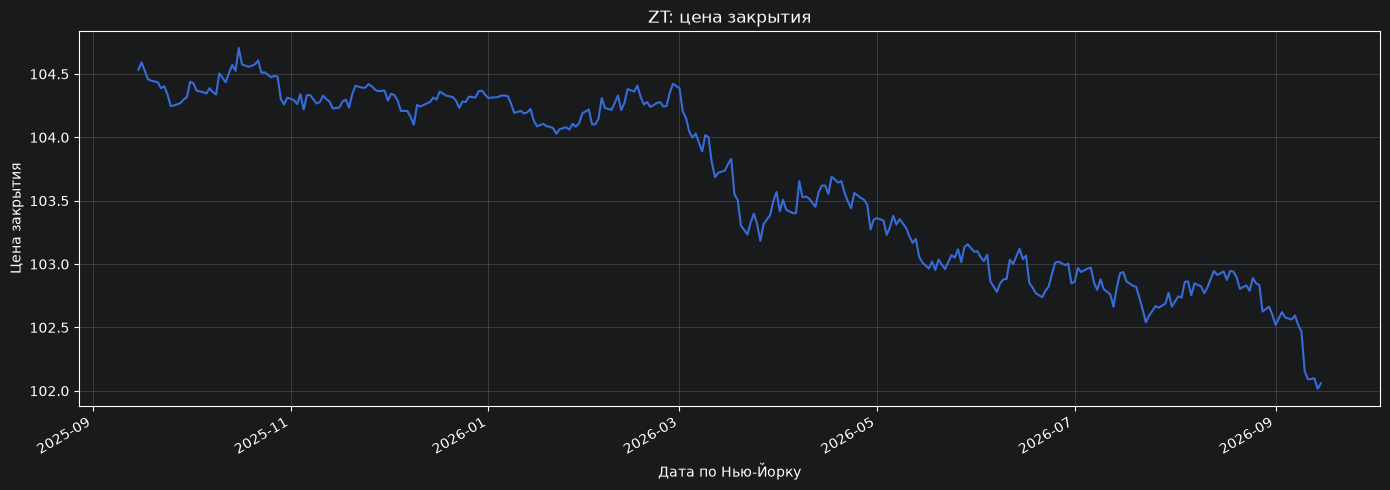

In [177]:
start_date = "2025-09-15"
end_date = "2026-09-15"

for df, top_n, label in [
    (stocks_5_min, 10, "Акции"),
    (futures_15_min, 3, "Фьючерсы"),
]:
    period = df.loc[df["ny_date"].between(
        pd.Timestamp(start_date).date(),
        pd.Timestamp(end_date).date(),
    )]
    top_volumes = period.groupby("ticker")["volume"].sum().nlargest(top_n)

    for ticker in top_volumes.index:
        plot_daily_close(df, ticker, start_date, end_date)


### Выше представлены графики цена закрытия для последнего бара за день.
### Были взяты топ 5 акций и топ 3 фьючерса по объему

### выводы:
1. Фьючам на казначейские облигации США не в интрадей сценарии плохо
2. Нетфликсу было плохо в конце 2025. Интересно в чем причина
3. На определенных учстках для разных акций прослеживаются определенные тренды. описывать их не буду. Из графиков видно

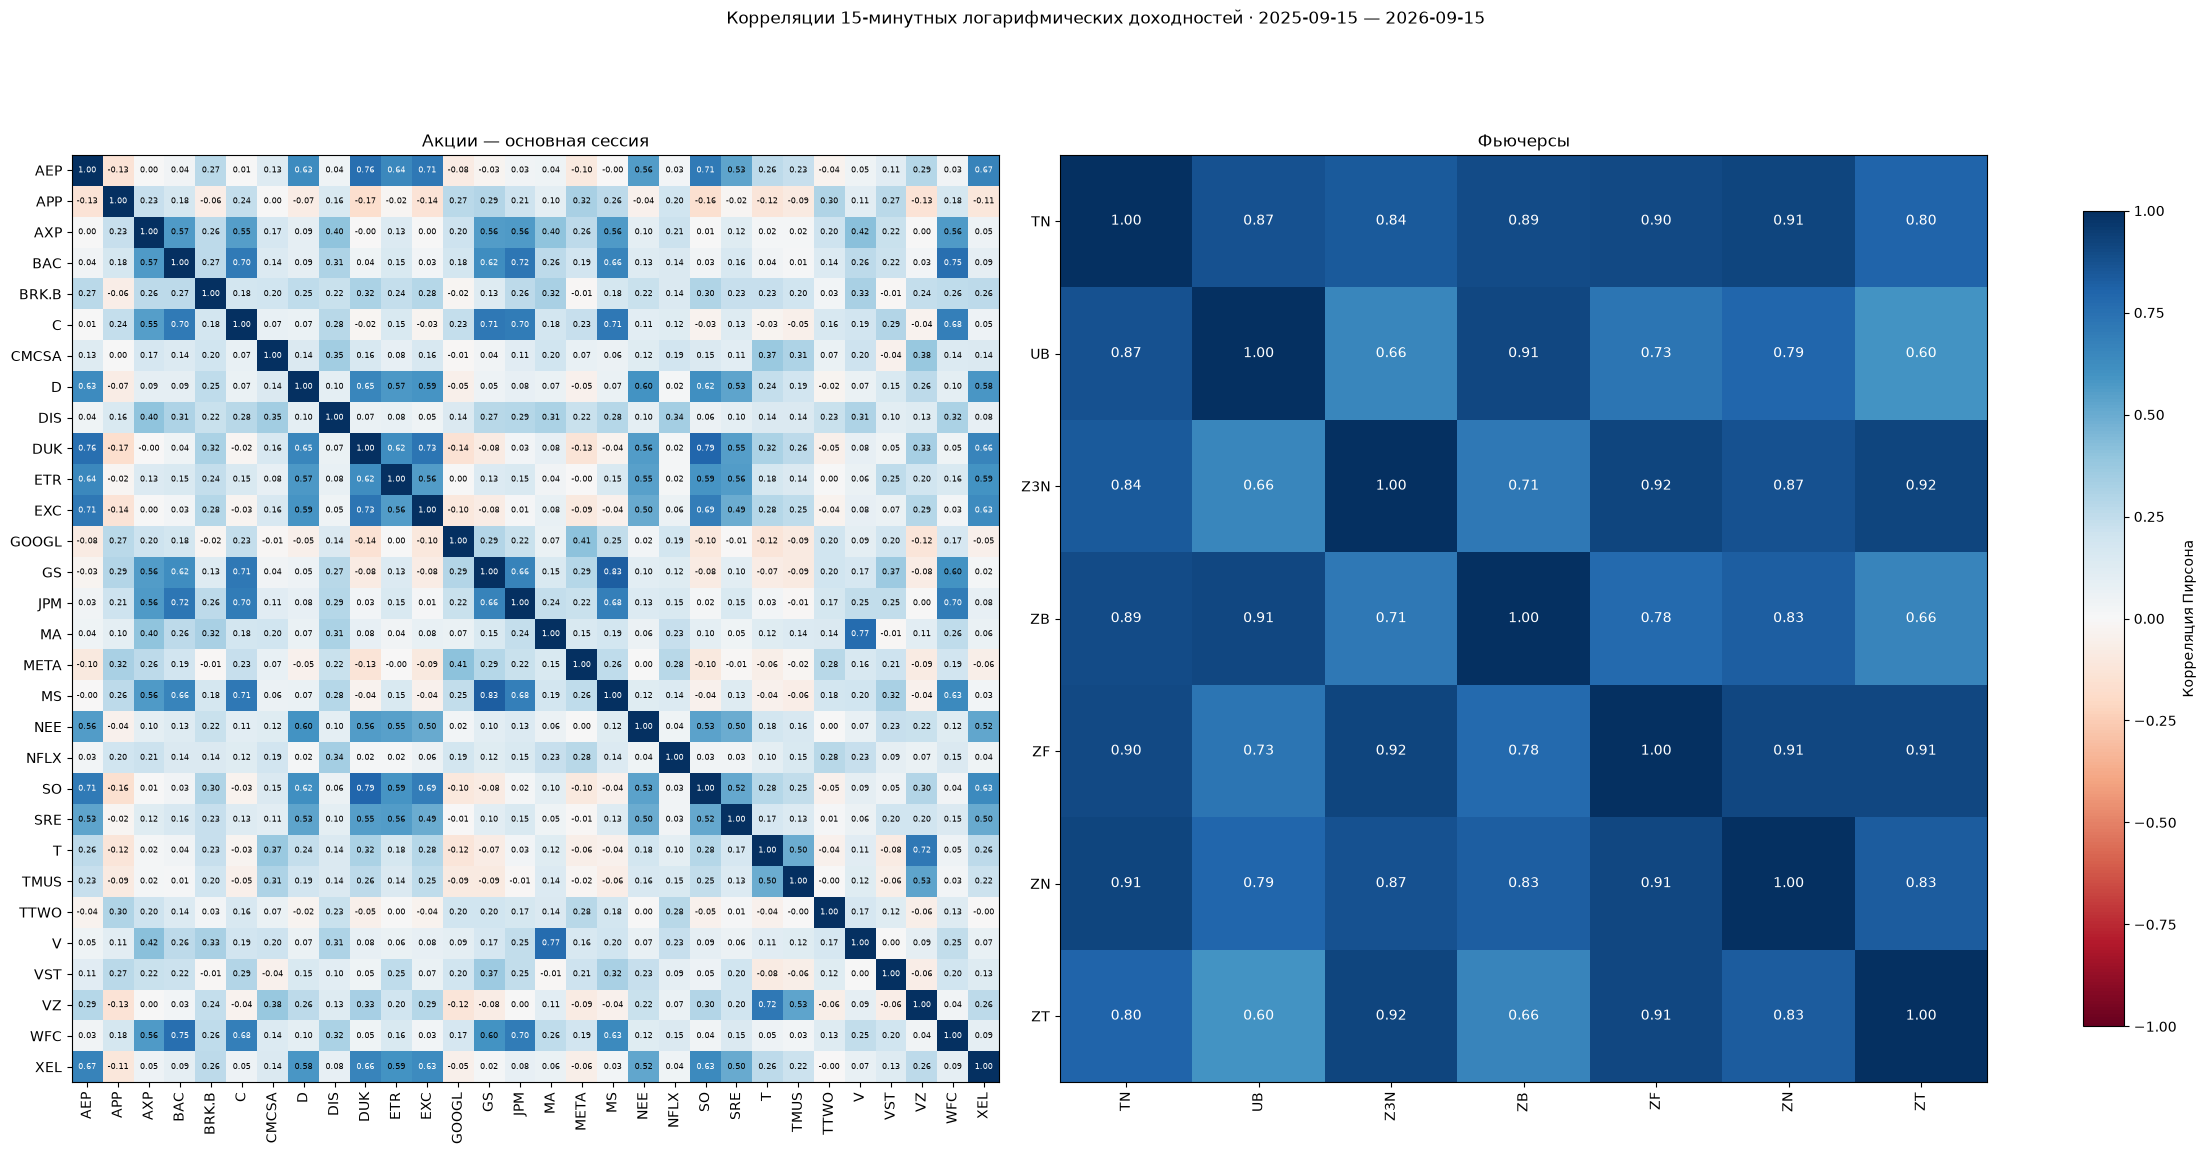

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

corr_start = "2025-09-15"
corr_end = "2026-09-15"

def prepare_return_correlations(df, is_stock):
    sample = df.copy()
    if is_stock:
        sample = sample.loc[sample["in_session"]].copy()
    sample = sample.loc[sample["ny_date"].between(
        pd.Timestamp(corr_start).date(), pd.Timestamp(corr_end).date(),
    )].copy()
    price = "adj_close" if is_stock else "close"
    session_key = "ny_date" if is_stock else "session_end_date"
    sample = sample.sort_values(["ticker", session_key, "utc_time"])
    grouped = sample.groupby(["ticker", session_key])
    previous_price = grouped[price].shift()
    previous_time = grouped["utc_time"].shift()
    consecutive = (sample["utc_time"] - previous_time).eq(pd.Timedelta(15, unit="min"))
    sample["corr_return"] = np.log(
        sample[price].where(sample[price] > 0)
        / previous_price.where(previous_price > 0)
    ).where(consecutive)

    time_keys = ["utc_time"] if is_stock else ["utc_time", "session_end_date"]
    # pivot не усредняет повторные строки: дубликаты ключа нужно исследовать отдельно.
    wide = sample.pivot(index=time_keys, columns="ticker", values="corr_return")
    wide = wide.replace([np.inf, -np.inf], np.nan)
    correlation = wide.corr(method="pearson", min_periods=100)
    available = wide.notna().astype("int64")
    pair_counts = available.T.dot(available)
    return correlation, pair_counts

stocks_return_corr, stocks_corr_pair_counts = prepare_return_correlations(stocks_15_min, True)
futures_return_corr, futures_corr_pair_counts = prepare_return_correlations(futures_15_min, False)

fig, axes = plt.subplots(1, 2, figsize=(22, 12), constrained_layout=True)
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("lightgray")
for ax, matrix, title in [
    (axes[0], stocks_return_corr, "Акции — основная сессия"),
    (axes[1], futures_return_corr, "Фьючерсы"),
]:
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=90)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
    ax.grid(False)
    for row in range(len(matrix)):
        for col in range(len(matrix)):
            value = matrix.iloc[row, col]
            if pd.notna(value):
                ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                        fontsize=6 if len(matrix) > 15 else 10,
                        color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=axes, shrink=0.7, label="Корреляция Пирсона")
fig.suptitle(f"Корреляции 15-минутных логарифмических доходностей · {corr_start} — {corr_end}")
plt.show()


### Тк у меня в ноутбуке схожие фьючерсы, то и корреляции доходности высокие
### По акциям конечно надо вглядеться, чтобы что-то найти. Но я вижу 1 пример: Bank of America коррелирует с Citi Group и JP Morgan. Что логично, вед они в 1 секторе

In [183]:
corr_start = "2025-09-15"
corr_end = "2026-09-15"

# corr(BAC(t), BAC/JPM/C(t − lag)): все доходности 15-минутные.
bank_returns = (
    stocks_15_min.loc[stocks_15_min["in_session"] & stocks_15_min["ticker"].isin(["BAC", "JPM", "C"])
                    & stocks_15_min["ny_date"].between(pd.Timestamp(corr_start).date(), pd.Timestamp(corr_end).date())]
    .pivot(index="ny_time", columns="ticker", values="log_return")
)
lag_correlations = pd.DataFrame({
    lag: bank_returns[["BAC", "JPM", "C"]].shift(freq=pd.Timedelta(lag, unit="min")).corrwith(bank_returns["BAC"])
    for lag in [0, 15, 30, 60]
}).T.rename_axis("Лаг, минут")
display(lag_correlations.round(4))


ticker,BAC,JPM,C
"Лаг, минут",,,
0,1.0000,0.7210,0.7049
15,0.0045,0.0107,0.0009
30,0.0226,0.0223,0.0308
60,0.0022,0.0027,-0.0025


### Попробовал посмотреть корреляцию доходности уже с лагом, чтобы узнать можно ли судить о доходности Bank of America в будущем по JP Morgan и City. Также посмотрел коррелицию с собственным лагом.
### Как видно, корреляции низкие

### Такой простой фичи очевидно недостаточно )
### Можно будет посмотреть на других парах тикеров, но это уже в следующий раз при подготовке модели